# TCC — Caminho D (v21)
## Valor de mercado de jogadores-temporada do Brasileirao

### Correcoes em relacao a v3

| # | Problema | Correcao |
|---|---|---|
| 1 | Checkpoint antigo restaurado em silencio; o `if X is None` pulava o recalculo | Checkpoints validados por colunas e anos; se nao baterem, sao descartados |
| 2 | Particoes cortavam dentro da mesma temporada | Particoes **por temporada**: treina nos anos anteriores, testa no seguinte |
| 3 | Secao 5 comparava a taxa paga com o valor real, nao com a estimativa | Usa a predicao do modelo treinado |
| 4 | Transferencias de julho a dezembro usavam a temporada em curso | `temporada_ref` e sempre a ultima **concluida** |
| 5 | `preco` do Cartola entrava sem ressalva | Isolado por flag, para rodar com e sem |
| 6 | Nomes repetidos: o pareamento escolhia um jogador arbitrario | Nomes ambiguos e colisoes sao descartados |
| 7 | Comparacao entre modelos sem teste possivel (4 particoes) | Wilcoxon sobre os erros de cada observacao |
| 8 | Premio relativo lido sem diagnostico de vies | Vies do modelo e referencia do Transfermarkt calculados |
| 9 | Nulos vindos do parquet quebravam a imputacao categorica | Categoricas convertidas para texto, com categoria propria para ausentes |
| 10 | Busca de hiperparametros falhava em silencio | Execucao interrompida quando a busca nao produz score valido |
| 11 | A celula de treinamento redefinia MODELOS e apagava os modelos adicionados | A chave EXECUTAR_MODELOS_COMPLETOS passou para dentro dela |
| 12 | Faltavam estratificacao, SHAP e predicao conforme | Acrescentadas nas Secoes 6, 7 e 8 |
| 13 | Grupo meteorico com 25 casos | Plano B aplicado: ascensoes fundidas |
| 14 | SHAP subamostrava o fundo para 100 casos | Passa a usar todo o conjunto de ajuste |
| 15 | Intervalo sem leitura pratica | Fator multiplicativo |
| 16 | 12,6% dos alvos eram de jogadores ja em outro clube | Alvo exige clube no BRA1 na data |
| 17 | Duvida sobre incluir o preco do Cartola | Tres especificacoes aninhadas (M1, M2, M3) |
| 18 | Variante normalizada da predicao conforme instavel | Removida |
| 19 | O filtro do alvo eliminava 31 das 50 exportacoes da Secao 5 | Amostra de aplicacao passa a usar as variaveis, nao o alvo |
| 20 | Modelo nao era comparado com a persistencia | Secao 4B: formulacao por variacao, persistencia como linha de base e painel de metricas |
| 21 | Secoes 5 a 8 usavam o modelo de nivel | Passam a usar o modelo de variacao (D1), agora o principal |
| 22 | Colinearidade (gols x gols por jogo, r=0,90) tornava sinais do SHAP ininterpretaveis | D1 usa so os totais; versao completa mantida como sensibilidade |
| 23 | Limiares de trajetoria deixavam metade da amostra no grupo volatil | Conjunto de limiares selecionavel, escolhido pela distribuicao |
| 24 | Tabela de cobertura sem os numeros de contaminacao e posicao ausente | Contagens calculadas diretamente |
| 25 | Resultados so agregados, sem mostrar o modelo em jogadores reais | Secao 9: casos individuais por regra fixa, amostra aleatoria, grafico e exportacoes |
| 26 | Decisoes pendentes com o orientador | Adotadas com base na literatura (ver tabela abaixo); sensibilidade D0, robustez por bootstrap e Diebold-Mariano, limiares nas duas versoes |
| 27 | `pontos` era a pontuacao da ULTIMA rodada (zero para ~50% dos atletas), nao o total da temporada | `pontos` = media x jogos; exportacoes ganham erro em log contra a taxa e sensibilidade sem possiveis emprestimos |
| 28 | Nao se sabia por que so 50 das 149 exportacoes eram avaliadas | Celula de funil na Secao 5 (nenhum resultado muda) |
| 29 | Orientador: verificar o RMSE frente a outliers e comparar metricas com os artigos | Secao 4C: painel completo (R2 log e euros, RMSE, MAE, MAPE) e RMSE com e sem outliers |
| 30 | Orientador: graficos de treino e teste e curvas de aprendizado | Secao 4D: metricas de treino e teste por particao e curvas de aprendizado na particao de 2025 |

### Decisoes metodologicas adotadas (13/10/2026, com base na literatura)

| # | Decisao | Base |
|---|---|---|
| D1 | O valor de mercado anterior e o ponto de partida; a persistencia e linha de base obrigatoria | Muller, Simons e Weinmann (2017); Hyndman e Koehler (2006) |
| D2 | Formulacao por variacao e o resultado principal; o modelo de nivel e reportado como complemento (o que o desempenho explica sozinho) | Muller et al. (2017) com coeficiente fixado em 1; sensibilidade com coeficiente livre (D0) |
| D3 | Limiares de trajetoria versao 2 (volatilidade >= 0,40 ou queda >= 0,50); versao 1 reportada no apendice | Pre-registro, regra de versionamento; P75 da distribuicao |
| D4 | Superioridade geral sobre a persistencia reportada com IC por bootstrap e Diebold-Mariano; conclusao central no sentido da revisao | Muller et al. (2017) usam Diebold-Mariano |

### Numeros esperados
Cartola: 570, 578, 578, 562, 560, 576 -> **3.424**
Pareados (sem ambiguidade): 164, 190, 223, 264, 257, 327 -> **1.425**
Com alvo valido: 161, 152, 184, 188, 224, 286 -> **1.195** (517 jogadores)

---
## Secao 0 - Setup com validacao de checkpoint

O carregamento confere se o arquivo salvo corresponde ao recorte atual. Um checkpoint gerado
por outra versao do codigo e descartado em vez de usado em silencio - foi essa a falha que
produziu 1.428 pares em vez de 1.749.

In [1]:
!pip install rapidfuzz -q

import os, re, json, glob, unicodedata, pickle
import numpy as np, pandas as pd, requests

from google.colab import drive
drive.mount('/content/drive')

pd.set_option("display.width", 200); pd.set_option("display.max_columns", 60)
RANDOM_STATE = 42; np.random.seed(RANDOM_STATE)

DADOS = "/content/drive/MyDrive/TCC"
CKPT  = "/content/drive/MyDrive/TCC/checkpoints_v10"  # pasta nova: o alvo mudou na v10
os.makedirs(CKPT, exist_ok=True)

ANOS = [2020, 2021, 2022, 2023, 2024, 2025]
SCOUTS = ['G','A','DS','FC','FS','FF','FD','FT','CA','CV','I','PI',
          'GC','GS','PP','PC','PS','DE','DP','SG']

# Colunas que cada checkpoint DEVE ter. Faltando alguma, o arquivo e de outra versao.
ESPERADO = {
 "cartola": ["gols_p_jogo","assist_p_jogo","desarmes_p_jogo",
             "finaliz_p_jogo","faltas_sof_p_jogo","nome_n","apelido_n"],
 "pareado": ["player_id","temporada","gols_p_jogo","nome_n"],
 "base_js": ["player_id","temporada","corte","data_alvo","tem_alvo","idade_no_corte",
             "liga_no_alvo"],   # coluna nova: invalida checkpoints anteriores a v10
}

def normalizar_nome(s):
    if pd.isna(s): return ""
    s = str(s).lower().strip()
    s = unicodedata.normalize("NFKD", s).encode("ascii","ignore").decode()
    return re.sub(r"\s+", " ", re.sub(r"[^a-z\s]", " ", s)).strip()

def carregar(nome, chave):
    """So devolve o checkpoint se ele passar na validacao de colunas e anos."""
    p = f"{CKPT}/{nome}.parquet"
    if not os.path.exists(p):
        print(f"  {nome}: ausente"); return None
    df = pd.read_parquet(p)
    faltam = [x for x in ESPERADO[chave] if x not in df.columns]
    if faltam:
        print(f"  {nome}: DESCARTADO (faltam colunas {faltam[:3]})")
        os.remove(p); return None
    if "temporada" in df.columns:
        anos_ck = sorted(df["temporada"].unique().tolist())
        if anos_ck != ANOS:
            print(f"  {nome}: DESCARTADO (anos {anos_ck} != {ANOS})")
            os.remove(p); return None
    print(f"  {nome}: {df.shape} restaurado e validado")
    return df

def salvar(df, nome):
    df.to_parquet(f"{CKPT}/{nome}.parquet"); print(f"  {nome}: {df.shape} salvo")

print("=== estado ===")
cartola = carregar("cartola", "cartola")
pareado = carregar("pareado", "pareado")
base_js = carregar("base_js", "base_js")
print("\nsetup ok")

Mounted at /content/drive
=== estado ===
  cartola: (3424, 39) restaurado e validado
  pareado: (1425, 40) restaurado e validado
  base_js: (1425, 54) restaurado e validado

setup ok


---
## Secao 1 - Cartola (tres formatos)

2020 e 2022-2025 em `rodada-NN.csv`; 2021 em `Mercado_NN.txt` (JSON, latin-1, scouts com
prefixo `scout.`). 2018-2019 ficam de fora: nao tem `jogos_num`, e naqueles anos `pontos_num`
e a pontuacao da rodada, nao o acumulado.

In [2]:
if cartola is None:
    import tarfile, io
    destino = "/content/caRtola"
    if not os.path.exists(destino):
        print("baixando repositorio (~27 MB)...")
        r = requests.get("https://codeload.github.com/henriquepgomide/caRtola/tar.gz/refs/heads/master",
                         timeout=300)
        tarfile.open(fileobj=io.BytesIO(r.content)).extractall("/content/")
        os.rename(glob.glob("/content/caRtola-*")[0], destino)

    def ultimo_arquivo(ano):
        csvs = glob.glob(f"{destino}/data/01_raw/{ano}/rodada-*.csv")
        if csvs:
            f = max(csvs, key=lambda p: int(re.search(r"rodada-(\d+)", p).group(1)))
            print(f"  {ano}: {os.path.basename(f)}")
            return pd.read_csv(f, engine="python"), "atletas.", ""
        txts = glob.glob(f"{destino}/data/01_raw/{ano}/Mercado_*.txt")
        if txts:
            f = max(txts, key=lambda p: int(re.search(r"Mercado_(\d+)", p).group(1)))
            print(f"  {ano}: {os.path.basename(f)} (JSON latin-1)")
            return pd.json_normalize(json.load(open(f, encoding="latin-1"))["atletas"]), "", "scout."
        raise FileNotFoundError(ano)

    def padronizar(df, P, S, ano):
        pega = lambda *cs: next((df[x] for x in cs if x in df.columns),
                                pd.Series([np.nan]*len(df)))
        o = pd.DataFrame()
        o["atleta_id"]  = pd.to_numeric(pega(P+"atleta_id","atleta_id"), errors="coerce")
        o["nome"]       = pega(P+"nome","nome").astype(str)
        o["apelido"]    = pega(P+"apelido","apelido").astype(str)
        o["clube_nome"] = pega(P+"clube.id.full.name","clube.id.full.name").astype(str)
        for d, s in [("posicao_id","posicao_id"),("jogos","jogos_num"),
                     ("media","media_num"),("pontos","pontos_num"),("preco","preco_num")]:
            o[d] = pd.to_numeric(pega(P+s, s), errors="coerce")
        for s in SCOUTS:
            o[s] = pd.to_numeric(pega(S+s, s), errors="coerce")
        o["temporada"] = ano
        return o

    cartola = pd.concat([padronizar(*ultimo_arquivo(a), a) for a in ANOS], ignore_index=True)

    # NaN em scout = evento nao ocorreu (a API so devolve o que existe) -> zero verdadeiro
    cartola[SCOUTS] = cartola[SCOUTS].fillna(0)

    POSICOES = {1:"goleiro",2:"lateral",3:"zagueiro",4:"meia",5:"atacante",6:"tecnico"}
    cartola["posicao"] = cartola["posicao_id"].map(POSICOES)
    cartola = cartola[(cartola["posicao"]!="tecnico") & (cartola["jogos"]>=3)].copy()

    j = cartola["jogos"].replace(0, np.nan)
    cartola["gols_p_jogo"]      = (cartola["G"]/j).fillna(0)
    cartola["assist_p_jogo"]    = (cartola["A"]/j).fillna(0)
    cartola["desarmes_p_jogo"]  = (cartola["DS"]/j).fillna(0)
    cartola["finaliz_p_jogo"]   = ((cartola["FF"]+cartola["FD"]+cartola["FT"])/j).fillna(0)
    cartola["faltas_sof_p_jogo"]= (cartola["FS"]/j).fillna(0)
    cartola["cartoes_p_jogo"]   = ((cartola["CA"]+cartola["CV"])/j).fillna(0)

    cartola["nome_n"]    = cartola["nome"].map(normalizar_nome)
    cartola["apelido_n"] = cartola["apelido"].map(normalizar_nome)
    salvar(cartola, "cartola")

print(cartola.groupby("temporada").size().to_string())
print("total:", len(cartola), "| esperado: 3424")

temporada
2020    570
2021    578
2022    578
2023    562
2024    560
2025    576
total: 3424 | esperado: 3424


---
## Secao 2 - Pareamento restrito por temporada

Para cada ano, o universo de candidatos e so quem o Transfermarkt registra em clube do BRA1
naquele ano. Isso reduz muito a ambiguidade de nomes repetidos.

In [3]:
players = pd.read_csv(f"{DADOS}/players.csv",
                      usecols=["player_id","name","date_of_birth","position",
                               "sub_position","foot","height_in_cm","country_of_citizenship"])
valuations = pd.read_csv(f"{DADOS}/player_valuations.csv",
                         usecols=["player_id","date","market_value_in_eur",
                                  "player_club_domestic_competition_id"])
valuations["date"] = pd.to_datetime(valuations["date"])
valuations["ano"]  = valuations["date"].dt.year

players = players.drop_duplicates("player_id")        # evita duplicar linhas no merge
players["nome_n"] = players["name"].map(normalizar_nome)

universo = (valuations[valuations["player_club_domestic_competition_id"]=="BRA1"]
            [["player_id","ano"]].drop_duplicates()
            .merge(players[["player_id","nome_n"]], on="player_id"))
print("pares (jogador, ano) no BRA1:", len(universo))
print(universo[universo["ano"].isin(ANOS)].groupby("ano").size().to_string())

pares (jogador, ano) no BRA1: 4910
ano
2020    306
2021    407
2022    447
2023    533
2024    527
2025    617


In [4]:
if pareado is None:
    partes, aud = [], []
    for t in ANOS:
        c_t  = cartola[cartola["temporada"]==t]
        pool_full = universo[universo["ano"]==t][["player_id","nome_n"]].drop_duplicates()
        # Nome compartilhado por 2+ jogadores no mesmo ano e ambiguo: nao ha como decidir -> excluido
        cont = pool_full.groupby("nome_n")["player_id"].nunique()
        ambiguos = int((cont > 1).sum())
        pool = pool_full[pool_full["nome_n"].isin(cont[cont == 1].index)]

        m1  = c_t.merge(pool, on="nome_n", how="left")
        ok1 = m1[m1["player_id"].notna()]

        falta = m1[m1["player_id"].isna()].drop(columns=["player_id"])
        m2  = falta.merge(pool.rename(columns={"nome_n":"apelido_n"}),
                          on="apelido_n", how="left")
        ok2 = m2[m2["player_id"].notna()]

        juntos = pd.concat([ok1, ok2])
        # Colisao: o mesmo jogador do Transfermarkt atribuido a 2+ atletas do Cartola -> todos descartados
        colide = juntos.duplicated("player_id", keep=False)
        partes.append(juntos[~colide])
        aud.append({"temporada":t, "cartola":len(c_t), "universo_TM":len(pool),
                    "nomes_ambiguos":ambiguos, "por_nome":len(ok1), "por_apelido":len(ok2),
                    "colisoes":int(colide.sum()), "pareado":int((~colide).sum())})

    pareado = pd.concat(partes, ignore_index=True)
    pareado["player_id"] = pareado["player_id"].astype(int)
    pareado = pareado.drop_duplicates(subset=["player_id","temporada"])
    salvar(pareado, "pareado")

    aud = pd.DataFrame(aud)
    aud["taxa_s_cartola"]  = (aud["pareado"]/aud["cartola"]*100).round(1)
    aud["taxa_s_universo"] = (aud["pareado"]/aud["universo_TM"]*100).round(1)
    aud.to_csv(f"{CKPT}/auditoria_pareamento.csv", index=False)
    print(aud.to_string(index=False))

print("\npares finais:", len(pareado), "| esperado: 1425")
assert sorted(pareado["temporada"].unique()) == ANOS, "faltam temporadas no pareamento"


pares finais: 1425 | esperado: 1425


> **Por que descartar em vez de escolher.** Quando dois jogadores do Transfermarkt tem o mesmo
> nome no mesmo ano, ou quando dois atletas do Cartola caem no mesmo jogador, nao ha informacao
> para decidir o par correto. A v4 escolhia o primeiro, o que introduzia pares errados: ao
> descarta-los, o R2 do Ridge subiu de 0,31 para cerca de 0,38, sinal de que eram ruido.
>
> **Duas taxas, duas leituras.** `taxa_s_cartola` sobe de ~37% para ~66% ao longo dos anos,
> refletindo o crescimento do acervo do Transfermarkt. `taxa_s_universo` - pareados sobre o que
> existe de fato - fica estavel em torno de 64%. E a segunda que mede a qualidade do metodo.
> Registre as duas na metodologia.

In [5]:
# Verificacao manual obrigatoria
checagem = pareado.sample(min(25, len(pareado)), random_state=RANDOM_STATE)[
    ["nome","apelido","clube_nome","temporada","player_id"]].copy()
checagem["nome_no_TM"] = checagem["player_id"].map(
    players.set_index("player_id")["name"].to_dict())
print(checagem.to_string(index=False))
print(f"\nnomes repetidos no Transfermarkt: {players.duplicated('nome_n', keep=False).sum()}")

                                nome        apelido  clube_nome  temporada  player_id       nome_no_TM
                   Thiago dos Santos  Thiago Santos  Fluminense       2023     346922    Thiago Santos
          Ronielson da Silva Barbosa           Rony   Palmeiras       2023     371009             Rony
                 Kauã Elias Nogueira     Kauã Elias  Fluminense       2024    1119009       Kauã Elias
                    Walter Kannemann      Kannemann      Grêmio       2023     145400 Walter Kannemann
       João Marcelo Messias Ferreira   João Marcelo    Cruzeiro       2024     744024     João Marcelo
        Caio Alexandre Souza e Silva Caio Alexandre   Fortaleza       2023     727751   Caio Alexandre
Lincoln Henrique Oliveira dos Santos        Lincoln  Bragantino       2024     351738          Lincoln
              Robson Alves de Barros   Robson Bambu       Vasco       2023     458715     Robson Bambu
            Everton Cardoso da Silva        Everton         284       202

---
## Secao 3 - Alvo e ordem temporal

Corte em 31 de dezembro da temporada; alvo e o primeiro valor publicado depois, dentro de
182 dias. Totais anuais nunca sao repartidos para simular janela de 12 meses.

In [6]:
JANELA_DIAS = 182   # decisao registrada em 13/10/2026

if base_js is None:
    p = pareado.copy()
    p["corte"]  = pd.to_datetime(p["temporada"].astype(str) + "-12-31")
    p["limite"] = p["corte"] + pd.Timedelta(days=JANELA_DIAS)

    cand = p[["player_id","temporada","corte","limite"]].merge(
        valuations[["player_id","date","market_value_in_eur",
                    "player_club_domestic_competition_id"]], on="player_id")
    cand = cand[(cand["date"] > cand["corte"]) & (cand["date"] <= cand["limite"])]

    # O alvo tem de ser o valor do jogador AINDA como atleta do Brasileirao.
    # Sem este filtro, 12,6% dos alvos eram valores ja atualizados para o novo clube,
    # contaminados pela propria transferencia que a Secao 5 tenta avaliar depois.
    antes = cand["player_id"].nunique()
    cand = cand[cand["player_club_domestic_competition_id"] == "BRA1"]
    print(f"alvos descartados por mudanca de clube: {antes - cand['player_id'].nunique()} jogadores")

    alvo = (cand.sort_values("date").groupby(["player_id","temporada"]).first()
            .reset_index()[["player_id","temporada","market_value_in_eur","date",
                            "player_club_domestic_competition_id"]]
            .rename(columns={"date":"data_alvo",
                             "player_club_domestic_competition_id":"liga_no_alvo"}))

    base_js = p.merge(alvo, on=["player_id","temporada"], how="left")
    base_js = base_js.merge(players.drop(columns=["nome_n"]), on="player_id", how="left")
    base_js["date_of_birth"]  = pd.to_datetime(base_js["date_of_birth"], errors="coerce")
    base_js["idade_no_corte"] = (base_js["corte"] - base_js["date_of_birth"]).dt.days / 365.25
    base_js["tem_alvo"]       = base_js["market_value_in_eur"].notna().astype(int)
    salvar(base_js, "base_js")

com_alvo = base_js[base_js["tem_alvo"]==1].copy()

assert (com_alvo["liga_no_alvo"] == "BRA1").all(), "ha alvo com jogador fora do BRA1"
violacoes = (com_alvo["data_alvo"] <= com_alvo["corte"]).sum()
print(f"violacoes de ordem temporal: {violacoes} (deve ser 0)")
assert violacoes == 0, "ALVO ANTERIOR AO DESEMPENHO"

tab = base_js.groupby("temporada").agg(
    pareados=("player_id","size"), com_alvo=("tem_alvo","sum")).astype(int)
tab["perda_pct"] = ((1 - tab["com_alvo"]/tab["pareados"])*100).round(1)
print("\n", tab.to_string())
print(f"\nTOTAL com alvo: {tab['com_alvo'].sum()} | esperado 1195")
print(f"jogadores unicos: {com_alvo['player_id'].nunique()} | esperado 517")
print(f"mediana: EUR {com_alvo['market_value_in_eur'].median():,.0f}")

violacoes de ordem temporal: 0 (deve ser 0)

            pareados  com_alvo  perda_pct
temporada                               
2020            164       161        1.8
2021            190       152       20.0
2022            223       184       17.5
2023            264       188       28.8
2024            257       224       12.8
2025            327       286       12.5

TOTAL com alvo: 1195 | esperado 1195
jogadores unicos: 517 | esperado 517
mediana: EUR 2,500,000


In [7]:
# Contagens calculadas diretamente, sem depender do recalculo da Secao 3
p_ = pareado[["player_id","temporada"]].copy()
p_["corte"]  = pd.to_datetime(p_["temporada"].astype(str) + "-12-31")
p_["limite"] = p_["corte"] + pd.Timedelta(days=JANELA_DIAS)
w = p_.merge(valuations[["player_id","date","player_club_domestic_competition_id"]], on="player_id")
w = w[(w["date"] > w["corte"]) & (w["date"] <= w["limite"])]
com_valor_janela = set(map(tuple, w[["player_id","temporada"]].drop_duplicates().values))
com_valor_bra1   = set(map(tuple, w[w["player_club_domestic_competition_id"]=="BRA1"]
                              [["player_id","temporada"]].drop_duplicates().values))
n_sem_valor = len(p_) - len(com_valor_janela)
n_contam    = len(com_valor_janela - com_valor_bra1)
n_pos_desc  = int(base_js.loc[base_js["tem_alvo"]==1, "posicao"].isna().sum())

cobertura = pd.DataFrame([
 {"situacao":"Jogador do Cartola com 3+ jogos", "tratamento":"observado", "n": len(cartola)},
 {"situacao":"Scout ausente no Cartola", "tratamento":"zero verdadeiro", "n":"evento nao ocorreu"},
 {"situacao":"Sem par no Transfermarkt", "tratamento":"excluido, contabilizado", "n": len(cartola) - len(pareado)},
 {"situacao":"Pareado, sem nenhum valor na janela", "tratamento":"excluido, contabilizado", "n": n_sem_valor},
 {"situacao":"Valor na janela, mas ja em outro clube", "tratamento":"excluido (contaminacao)", "n": n_contam},
 {"situacao":"Posicao ausente no Cartola", "tratamento":"categoria propria; posicao do Transfermarkt mantida", "n": n_pos_desc},
 {"situacao":"Temporadas 2018-2019", "tratamento":"ausencia estrutural", "n":"excluidas (sem jogos_num)"},
])
print(cobertura.to_string(index=False))
print(f"\nconferencia: {len(pareado)} pareados - {n_sem_valor} sem valor - {n_contam} contaminados "
      f"= {len(pareado) - n_sem_valor - n_contam} (com alvo valido: {int(base_js['tem_alvo'].sum())})")
cobertura.to_csv(f"{CKPT}/tabela_cobertura.csv", index=False)

                              situacao                                          tratamento                         n
       Jogador do Cartola com 3+ jogos                                           observado                      3424
              Scout ausente no Cartola                                     zero verdadeiro        evento nao ocorreu
              Sem par no Transfermarkt                             excluido, contabilizado                      1999
   Pareado, sem nenhum valor na janela                             excluido, contabilizado                        60
Valor na janela, mas ja em outro clube                             excluido (contaminacao)                       170
            Posicao ausente no Cartola categoria propria; posicao do Transfermarkt mantida                       161
                  Temporadas 2018-2019                                 ausencia estrutural excluidas (sem jogos_num)

conferencia: 1425 pareados - 60 sem valor - 170 contaminados = 

---
## Secao 4 - Modelagem

### Particoes por temporada

**Correcao em relacao a v3.** Antes as particoes eram posicionais, o que cortava dentro da
mesma temporada - parte de um ano ia para treino e parte para teste, sem sentido temporal.
Como so existem 6 datas de corte distintas, o natural e partir por temporada.

In [8]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Dois quadros distintos:
#   dados_full = TODOS os jogadores-temporada pareados, com as variaveis preenchidas.
#                Usado para prever na Secao 5 - inclusive quem foi vendido e por isso
#                nao tem valor de mercado valido como atleta do Brasileirao.
#   dados      = subconjunto com alvo valido. Usado para TREINAR.
# Sem essa separacao, o filtro do alvo eliminaria justamente os jogadores exportados,
# que sao o objeto da amostra de aplicacao.
dados_full = base_js.sort_values(["temporada","player_id"]).reset_index(drop=True).copy()
for col in ["posicao","position","sub_position","foot"]:
    dados_full[col] = dados_full[col].where(dados_full[col].notna(), "desconhecido").astype(str)

# CORRECAO v18: no Cartola, pontos_num e a pontuacao da ULTIMA rodada do arquivo (zero para
# quem nao jogou nela - cerca de metade dos atletas em todos os anos), e nao o total da
# temporada. O total correto e media_num (media por jogo disputado) x jogos_num.
dados_full["pontos"] = dados_full["media"] * dados_full["jogos"]
print(f"pontos da temporada (media x jogos): mediana {dados_full['pontos'].median():.1f} | "
      f"zeros {(dados_full['pontos'] == 0).mean():.1%} | corr. com jogos {dados_full['pontos'].corr(dados_full['jogos']):.2f}")

dados = dados_full[dados_full["tem_alvo"] == 1].reset_index(drop=True)
print(f"pareados: {len(dados_full)} | com alvo valido (treinamento): {len(dados)}")
print("posicao ausente no Cartola:", (dados["posicao"]=="desconhecido").sum(), "de", len(dados))

# Tres especificacoes aninhadas, em vez de decidir arbitrariamente sobre o preco:
#   M1 desempenho e atributos            -> responde a pergunta do trabalho
#   M2 M1 mais o preco do Cartola        -> mede o ganho de uma cotacao de mercado
#   M3 so preco e idade                  -> mostra quanto o preco carrega sozinho
DESEMPENHO = ["jogos","media","pontos","gols_p_jogo","assist_p_jogo","desarmes_p_jogo",
              "finaliz_p_jogo","faltas_sof_p_jogo","cartoes_p_jogo","G","A","DS","FS","FC"]
ATRIBUTOS  = ["idade_no_corte","height_in_cm"]
CAT_COMPLETA = ["posicao","position","sub_position","foot"]

ESPECIFICACOES = {
    "M1 (sem preco)":      (ATRIBUTOS + DESEMPENHO,            CAT_COMPLETA),
    "M2 (com preco)":      (ATRIBUTOS + DESEMPENHO + ["preco"], CAT_COMPLETA),
    "M3 (so preco+idade)": (["idade_no_corte","preco"],        []),
}
ESPEC_PRINCIPAL = "M1 (sem preco)"     # decisao D2 (13/10/2026)

def montar(nome):
    num, cat = ESPECIFICACOES[nome]
    passos = [("num", Pipeline([("imp",SimpleImputer(strategy="median")),
                                ("sc",StandardScaler())]), num)]
    if cat:
        passos.append(("cat", Pipeline([("oh",OneHotEncoder(handle_unknown="ignore"))]), cat))
    return ColumnTransformer(passos), dados[num + cat]

preproc, X = montar(ESPEC_PRINCIPAL)
NUMERICAS, CATEGORICAS = ESPECIFICACOES[ESPEC_PRINCIPAL]
y = np.log1p(dados["market_value_in_eur"])
grupos = dados["player_id"].values
temporadas = dados["temporada"].values
print(f"\nespecificacao principal: {ESPEC_PRINCIPAL} | X: {X.shape}")

pontos da temporada (media x jogos): mediana 59.2 | zeros 0.0% | corr. com jogos 0.77
pareados: 1425 | com alvo valido (treinamento): 1195
posicao ausente no Cartola: 161 de 1195

especificacao principal: M1 (sem preco) | X: (1195, 20)


In [9]:
def folds_por_temporada(temporadas, grupos, anos=ANOS, min_treino=2):
    """Treina nas temporadas anteriores, testa na seguinte.
    Remove do treino jogadores presentes no teste - o mesmo atleta repete anos."""
    for i in range(min_treino, len(anos)):
        ano_teste = anos[i]
        te = np.where(temporadas == ano_teste)[0]
        tr = np.where(temporadas < ano_teste)[0]
        jog_te = set(grupos[te])
        tr = np.array([k for k in tr if grupos[k] not in jog_te])
        if len(tr) and len(te):
            yield tr, te, ano_teste

folds = list(folds_por_temporada(temporadas, grupos))
for tr, te, ano in folds:
    assert not (set(grupos[tr]) & set(grupos[te])), "VAZAMENTO"
    assert temporadas[tr].max() < ano, "TREINO NO FUTURO"
    print(f"teste {ano}: treino={len(tr):4d} teste={len(te):4d}")
print(f"\n{len(folds)} particoes, sem sobreposicao de jogadores.")

teste 2022: treino= 124 teste= 184
teste 2023: treino= 255 teste= 188
teste 2024: treino= 316 teste= 224
teste 2025: treino= 388 teste= 286

4 particoes, sem sobreposicao de jogadores.


### Comparacao entre especificacoes

Roda o Ridge nas tres especificacoes, com as mesmas particoes. Se M3 chegar perto de M1, o
preco do Cartola equivale, sozinho, a todo o conjunto de variaveis de desempenho - achado que
precisa ser discutido no texto.

In [10]:
from sklearn.linear_model import Ridge
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

comp = []
for nome_esp in ESPECIFICACOES:
    pre_e, X_e = montar(nome_esp)
    r2s, maes = [], []
    for tr, te, ano in folds:
        b = RandomizedSearchCV(Pipeline([("preproc",pre_e),("modelo",Ridge())]),
                               {"modelo__alpha": np.logspace(-3,3,20)}, n_iter=20, cv=3,
                               scoring="neg_root_mean_squared_error",
                               random_state=RANDOM_STATE, n_jobs=-1).fit(X_e.iloc[tr], y.iloc[tr])
        p = b.best_estimator_.predict(X_e.iloc[te])
        r2s.append(r2_score(y.iloc[te], p))
        maes.append(mean_absolute_error(np.expm1(y.iloc[te]), np.expm1(p)))
    comp.append({"especificacao":nome_esp, "n_variaveis":X_e.shape[1],
                 "R2_medio":np.mean(r2s), "R2_dp":np.std(r2s, ddof=1), "MAE_eur":np.mean(maes)})

comp = pd.DataFrame(comp).round(3)
print(comp.to_string(index=False))
comp.to_csv(f"{CKPT}/comparacao_especificacoes.csv", index=False)

      especificacao  n_variaveis  R2_medio  R2_dp     MAE_eur
     M1 (sem preco)           20     0.340  0.030 2171321.890
     M2 (com preco)           21     0.414  0.065 2113269.048
M3 (so preco+idade)            2     0.320  0.089 2288115.070


> Remover do treino os jogadores presentes no teste reduz bastante o conjunto de treino,
> porque muitos atletas aparecem em varias temporadas. E o preco de nao vazar identidade -
> sem isso, o modelo reconheceria o jogador em vez de aprender o padrao. Reporte o tamanho
> efetivo de treino de cada particao na metodologia.

In [11]:
# A chave fica AQUI, na mesma celula do treinamento.
# Na v6 ela estava numa celula separada e esta linha apagava os modelos adicionados.
EXECUTAR_MODELOS_COMPLETOS = True     # False = so Media e Ridge

def metricas(yr, yp):
    r, p = np.expm1(yr), np.expm1(yp)
    return {"MAE_eur": mean_absolute_error(r,p),
            "RMSE_eur": np.sqrt(mean_squared_error(r,p)),
            "R2_log": r2_score(yr, yp)}

MODELOS = {
    "Media (trivial)": (DummyRegressor(strategy="mean"), {}),
    "Ridge": (Ridge(), {"modelo__alpha": np.logspace(-3,3,20)}),
}

if EXECUTAR_MODELOS_COMPLETOS:
    from sklearn.ensemble import RandomForestRegressor
    from xgboost import XGBRegressor
    MODELOS.update({
      "RandomForest": (RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1), {
         "modelo__n_estimators":[200,400,800], "modelo__max_depth":[None,6,10,16],
         "modelo__min_samples_leaf":[1,2,5,10], "modelo__max_features":["sqrt",0.5,1.0]}),
      "XGBoost": (XGBRegressor(random_state=RANDOM_STATE, n_jobs=-1, tree_method="hist"), {
         "modelo__n_estimators":[300,600,1000], "modelo__max_depth":[3,5,7,9],
         "modelo__learning_rate":[0.01,0.03,0.1], "modelo__subsample":[0.7,0.85,1.0],
         "modelo__colsample_bytree":[0.7,0.85,1.0], "modelo__reg_lambda":[0.1,1.0,10.0]}),
    })

print("modelos a treinar:", list(MODELOS.keys()), "\n")

resultados = []
predicoes  = {n: np.full(len(dados), np.nan) for n in MODELOS}
modelos_treinados = {}

for nome,(est,grade) in MODELOS.items():
    print(f"=== {nome} ===")
    for tr, te, ano in folds:
        pipe = Pipeline([("preproc",preproc),("modelo",est)])
        if grade:
            b = RandomizedSearchCV(pipe, grade, n_iter=20, cv=3,
                                   scoring="neg_root_mean_squared_error",
                                   random_state=RANDOM_STATE, n_jobs=-1)
            b.fit(X.iloc[tr], y.iloc[tr]); melhor = b.best_estimator_
            if not np.isfinite(b.best_score_):
                raise RuntimeError(f"busca sem score valido em {nome}/{ano}")
        else:
            pipe.fit(X.iloc[tr], y.iloc[tr]); melhor = pipe
        pred = melhor.predict(X.iloc[te]); predicoes[nome][te] = pred
        modelos_treinados[(nome, ano)] = melhor
        m = metricas(y.iloc[te].values, pred); m.update({"modelo":nome,"ano_teste":ano})
        resultados.append(m)
        print(f"  {ano}: RMSE EUR {m['RMSE_eur']:>11,.0f} | MAE EUR {m['MAE_eur']:>10,.0f} | R2 {m['R2_log']:+.3f}")
    print()

res = pd.DataFrame(resultados)
print("--- media entre as particoes ---")
for nome,g in res.groupby("modelo"):
    print(f"{nome:18s} MAE EUR {g['MAE_eur'].mean():>10,.0f} | "
          f"RMSE EUR {g['RMSE_eur'].mean():>11,.0f} | R2 {g['R2_log'].mean():+.3f} +/- {g['R2_log'].std():.3f}")

with open(f"{CKPT}/resultados_modelos.pkl","wb") as f:
    pickle.dump({"res":res,"predicoes":predicoes}, f)

modelos a treinar: ['Media (trivial)', 'Ridge', 'RandomForest', 'XGBoost'] 

=== Media (trivial) ===
  2022: RMSE EUR   3,875,120 | MAE EUR  2,357,668 | R2 -0.046
  2023: RMSE EUR   5,327,315 | MAE EUR  2,539,307 | R2 -0.022
  2024: RMSE EUR   5,661,759 | MAE EUR  2,984,731 | R2 -0.044
  2025: RMSE EUR   4,986,624 | MAE EUR  2,820,538 | R2 -0.001

=== Ridge ===
  2022: RMSE EUR   3,056,044 | MAE EUR  1,935,888 | R2 +0.332
  2023: RMSE EUR   4,264,509 | MAE EUR  2,078,696 | R2 +0.348
  2024: RMSE EUR   4,290,777 | MAE EUR  2,446,186 | R2 +0.304
  2025: RMSE EUR   3,726,127 | MAE EUR  2,224,518 | R2 +0.376

=== RandomForest ===
  2022: RMSE EUR   3,370,565 | MAE EUR  2,217,630 | R2 +0.119
  2023: RMSE EUR   4,607,876 | MAE EUR  2,176,685 | R2 +0.291
  2024: RMSE EUR   4,828,881 | MAE EUR  2,587,015 | R2 +0.285
  2025: RMSE EUR   4,078,644 | MAE EUR  2,297,277 | R2 +0.427

=== XGBoost ===
  2022: RMSE EUR   3,764,184 | MAE EUR  2,513,091 | R2 -0.079
  2023: RMSE EUR   4,912,376 | MAE EUR 

### Teste de significancia

Com apenas 4 particoes, um teste sobre as metricas agregadas nao tem poder algum (o menor p
possivel no Wilcoxon com n=4 e 0,125). A comparacao e feita sobre os **erros absolutos de cada
observacao de teste**, pareados entre modelos.

In [12]:
from scipy.stats import wilcoxon
from itertools import combinations

mask = ~np.isnan(predicoes["Ridge"])
real_eur = np.expm1(y.values)
erros = {n: np.abs(real_eur - np.expm1(predicoes[n])) for n in predicoes}
print(f"observacoes de teste: {mask.sum()}\n")
for a, b in combinations(predicoes.keys(), 2):
    ea, eb = erros[a][mask], erros[b][mask]
    p = wilcoxon(ea, eb).pvalue
    menor = a if np.median(ea) < np.median(eb) else b
    print(f"{a:18s} vs {b:18s} p = {p:.2e} | menor erro mediano: {menor}")

observacoes de teste: 882

Media (trivial)    vs Ridge              p = 4.28e-23 | menor erro mediano: Ridge
Media (trivial)    vs RandomForest       p = 1.94e-21 | menor erro mediano: RandomForest
Media (trivial)    vs XGBoost            p = 3.19e-17 | menor erro mediano: XGBoost
Ridge              vs RandomForest       p = 2.94e-04 | menor erro mediano: RandomForest
Ridge              vs XGBoost            p = 4.81e-06 | menor erro mediano: Ridge
RandomForest       vs XGBoost            p = 1.17e-03 | menor erro mediano: RandomForest


> **Criterio para prosseguir.** O Ridge precisa superar a media trivial em todas as particoes.
> Se nao superar, o problema esta nas variaveis ou no pareamento - modelos mais complexos nao
> resolvem. Depois de validado, mude `EXECUTAR_MODELOS_COMPLETOS` para `True` na mesma celula e reexecute-a. Rode tambem com `USAR_PRECO = False`: se a diferenca for grande, o preco do fantasy
> game esta carregando boa parte da predicao, e isso precisa ser discutido no texto.

In [13]:
# (celula desativada na v7 — a chave passou para a celula de treinamento)
print("ver EXECUTAR_MODELOS_COMPLETOS na celula de treinamento")

ver EXECUTAR_MODELOS_COMPLETOS na celula de treinamento


---
## Secao 4B - Formulacao por variacao (seguindo Muller, Simons e Weinmann, 2017)

Resposta as observacoes do orientador. O modelo de nivel (R2 0,33) perde para a simples
repeticao do ultimo valor publicado (R2 0,94). A referencia central da area usa o valor
defasado como preditor. Aqui o modelo preve a **variacao** do valor e o nivel e reconstruido
somando essa variacao ao valor anterior - assim o coeficiente do valor anterior fica fixo em 1
e o modelo so precisa explicar o que muda.

Linha de base obrigatoria: a **persistencia** (repetir o valor anterior).

In [14]:
from scipy.stats import wilcoxon, binomtest

val_c = pd.read_csv(f"{DADOS}/player_valuations.csv",
                    usecols=["player_id","date","market_value_in_eur","current_club_id"])
val_c["date"] = pd.to_datetime(val_c["date"])

# Valor anterior e clube na data de corte (so informacao anterior ao corte)
ant = val_c.rename(columns={"market_value_in_eur":"v_ant","date":"d_ant","current_club_id":"clube_ant"})
mv = dados.merge(ant, on="player_id")
mv = (mv[mv["d_ant"] < mv["corte"]].sort_values("d_ant")
        .groupby(["player_id","temporada"]).last().reset_index())

# Forca do clube: mediana do ultimo valor de cada jogador do elenco nos 12 meses antes do corte
fc = []
for t in sorted(mv["temporada"].unique()):
    corte = pd.Timestamp(f"{t}-12-31")
    w = (val_c[(val_c["date"] < corte) & (val_c["date"] >= corte - pd.Timedelta(days=365))]
           .sort_values("date").groupby("player_id").last())
    g = w.groupby("current_club_id")["market_value_in_eur"].median().rename("clube_mediana").reset_index()
    g["temporada"] = t; fc.append(g)
fc = pd.concat(fc).rename(columns={"current_club_id":"clube_ant"})
mv = mv.merge(fc, on=["clube_ant","temporada"], how="left")
mv["clube_mediana_log"] = np.log1p(mv["clube_mediana"])

# Desempenho da temporada anterior do mesmo jogador
cols_ant = ["media","jogos","gols_p_jogo","assist_p_jogo"]
tant = dados[["player_id","temporada"] + cols_ant].copy(); tant["temporada"] += 1
tant = tant.rename(columns={c: c + "_ant" for c in cols_ant})
mv = mv.merge(tant, on=["player_id","temporada"], how="left")
mv["tem_temp_ant"] = mv["media_ant"].notna().astype(int)

mv = mv.sort_values(["temporada","player_id"]).reset_index(drop=True)
mv["v_ant_log"] = np.log1p(mv["v_ant"])
mv["y"]         = np.log1p(mv["market_value_in_eur"])
mv["delta"]     = mv["y"] - mv["v_ant_log"]
print(f"observacoes com valor anterior: {len(mv)} | com temporada anterior: {mv['tem_temp_ant'].mean():.0%}")
print(f"variacao em log: media {mv['delta'].mean():.3f} | dp {mv['delta'].std():.3f} | "
      f"valores que mudaram: {(mv['delta'].abs()>0.01).mean():.0%}")

observacoes com valor anterior: 1195 | com temporada anterior: 49%
variacao em log: media 0.024 | dp 0.316 | valores que mudaram: 60%


In [15]:
# Especificacao enxuta: so os totais da temporada.
# A versao completa tinha pares quase redundantes (gols x gols por jogo, r = 0,90;
# assistencias x assistencias por jogo, 0,89; desarmes x desarmes por jogo, 0,84).
# Com essa colinearidade o sinal de cada coeficiente deixa de ser interpretavel, e o
# desempenho preditivo nao muda ao remover a redundancia.
DES          = ATRIBUTOS + ["jogos","pontos","G","A","DS","FS","FC"]
DES_COMPLETO = ATRIBUTOS + DESEMPENHO

ESPEC_VAR = {
    "D1 variacao, desempenho":              DES,
    "D1b variacao, totais + por jogo":      DES_COMPLETO,     # sensibilidade
    "D2 variacao, + forca do clube":        DES + ["clube_mediana_log"],
    "D3 variacao, + clube + temp. anterior": DES + ["clube_mediana_log","media_ant","jogos_ant",
                                                    "gols_p_jogo_ant","assist_p_jogo_ant","tem_temp_ant"],
}
gv, tv = mv["player_id"].values, mv["temporada"].values

def prever_var(num, alvo):
    pre = ColumnTransformer([
        ("num", Pipeline([("imp",SimpleImputer(strategy="median")),("sc",StandardScaler())]), num),
        ("cat", Pipeline([("oh",OneHotEncoder(handle_unknown="ignore"))]), CAT_COMPLETA)])
    Xv = mv[num + CAT_COMPLETA]; out = np.full(len(mv), np.nan)
    for ano in ANOS[2:]:
        te = np.where(tv == ano)[0]; tr = np.where(tv < ano)[0]
        s = set(gv[te]); tr = np.array([k for k in tr if gv[k] not in s])
        b = RandomizedSearchCV(Pipeline([("p",pre),("m",Ridge())]), {"m__alpha": np.logspace(-2,4,25)},
                               n_iter=25, cv=3, random_state=RANDOM_STATE, n_jobs=-1).fit(Xv.iloc[tr], mv[alvo].iloc[tr])
        if not np.isfinite(b.best_score_): raise RuntimeError(f"busca sem score em {ano}")
        out[te] = b.best_estimator_.predict(Xv.iloc[te])
    return out

pred_var = {"Persistencia": mv["v_ant_log"].values.copy(),
            "M1 nivel, desempenho": prever_var(DES_COMPLETO, "y")}   # igual a Secao 4
for nome, num in ESPEC_VAR.items():
    pred_var[nome] = mv["v_ant_log"].values + prever_var(num, "delta")
# Sensibilidade (Muller, Simons e Weinmann, 2017): modelo de NIVEL com o valor anterior como
# preditor de coeficiente LIVRE. Na formulacao por variacao (D1) esse coeficiente e fixado em 1.
NOME_MULLER = "D0 nivel + valor anterior livre (Muller et al.)"
pred_var[NOME_MULLER] = prever_var(DES + ["v_ant_log"], "y")
print("ok")

ok


### Painel de metricas

Cada metrica conta uma parte da historia: erro mediano e MdAPE descrevem o caso tipico; MAE o
impacto financeiro agregado; o ganho sobre a persistencia mostra se o modelo acrescenta algo
ao que o mercado ja sabia.

In [16]:
kv = ~np.isnan(pred_var["M1 nivel, desempenho"])
yl, real = mv["y"].values[kv], mv["market_value_in_eur"].values[kv]
pp = pred_var["Persistencia"][kv]; ep = np.abs(yl - pp)

painel = []
for nome, p in pred_var.items():
    pl = p[kv]; est = np.expm1(pl); e = np.abs(yl - pl); raz = est / real
    painel.append({"estrategia": nome,
        "R2_log": r2_score(yl, pl),
        "MAE_eur": mean_absolute_error(real, est),
        "erro_mediano_eur": np.median(np.abs(real - est)),
        "MdAPE_pct": np.median(np.abs(est - real) / real) * 100,
        "fator2_pct": ((raz >= .5) & (raz <= 2)).mean() * 100,
        "ganho_MSE_vs_persist_pct": (1 - mean_squared_error(yl, pl) / mean_squared_error(yl, pp)) * 100,
        "p_wilcoxon_vs_persist": (wilcoxon(e, ep).pvalue if nome != "Persistencia" else np.nan)})
painel = pd.DataFrame(painel)
print(f"observacoes de teste: {kv.sum()}\n")
print(painel.round(3).to_string(index=False))
painel.to_csv(f"{CKPT}/painel_metricas.csv", index=False)

observacoes de teste: 882

                                     estrategia  R2_log     MAE_eur  erro_mediano_eur  MdAPE_pct  fator2_pct  ganho_MSE_vs_persist_pct  p_wilcoxon_vs_persist
                                   Persistencia   0.942  476870.748        100000.000     12.000      96.939                     0.000                    NaN
                           M1 nivel, desempenho   0.346 2194978.195       1179271.644     54.585      53.288                 -1030.857                  0.000
                        D1 variacao, desempenho   0.948  555675.899        250812.931     10.407      97.619                    10.102                  0.009
                D1b variacao, totais + por jogo   0.948  549470.348        249012.767     10.497      97.619                     9.696                  0.008
                  D2 variacao, + forca do clube   0.948  552184.828        249025.944     10.508      97.619                    10.149                  0.008
          D3 variacao, + 

### Sensibilidade: coeficiente do valor anterior

Muller, Simons e Weinmann (2017) usam o valor anterior como preditor com coeficiente estimado.
A formulacao por variacao fixa esse coeficiente em 1 para isolar o que o desempenho acrescenta.
A linha D0 do painel mostra o desempenho preditivo com o coeficiente livre; a celula abaixo mostra
o valor estimado. Coeficiente abaixo de 1 indica regressao a media (valores altos tendem a cair,
baixos a subir); se o painel mostrar D0 e D1 proximos, a restricao nao custa precisao.

In [17]:
NUM0 = DES + ["v_ant_log"]
ano_ult = max(ANOS)
tr0 = np.where(tv < ano_ult)[0]
s0 = set(gv[tv == ano_ult]); tr0 = np.array([k for k in tr0 if gv[k] not in s0])
pre0 = ColumnTransformer([
    ("num", Pipeline([("imp",SimpleImputer(strategy="median")),("sc",StandardScaler())]), NUM0),
    ("cat", Pipeline([("oh",OneHotEncoder(handle_unknown="ignore"))]), CAT_COMPLETA)])
b0 = RandomizedSearchCV(Pipeline([("p",pre0),("m",Ridge())]), {"m__alpha": np.logspace(-2,4,25)},
                        n_iter=25, cv=3, random_state=RANDOM_STATE, n_jobs=-1
                       ).fit(mv[NUM0 + CAT_COMPLETA].iloc[tr0], mv["y"].iloc[tr0])
m0 = b0.best_estimator_
sc0 = m0.named_steps["p"].named_transformers_["num"].named_steps["sc"]
j0 = NUM0.index("v_ant_log")
coef_vant = m0.named_steps["m"].coef_[j0] / sc0.scale_[j0]
print(f"treino {ANOS[0]}-{ano_ult-1} (n={len(tr0)})")
print(f"coeficiente do log do valor anterior no modelo D0: {coef_vant:.3f}  (D1 fixa em 1,000)")
lin = painel.set_index("estrategia").loc[["D1 variacao, desempenho", NOME_MULLER],
                                         ["R2_log","MdAPE_pct","ganho_MSE_vs_persist_pct"]]
print(); print(lin.round(3).to_string())

treino 2020-2024 (n=388)
coeficiente do log do valor anterior no modelo D0: 0.842  (D1 fixa em 1,000)

                                                 R2_log  MdAPE_pct  ganho_MSE_vs_persist_pct
estrategia                                                                                  
D1 variacao, desempenho                           0.948     10.407                    10.102
D0 nivel + valor anterior livre (Muller et al.)   0.936     16.324                   -11.084


### Onde o modelo ganha e onde perde

Em parte dos casos o Transfermarkt nao atualiza o valor entre dois registros: ali a persistencia
acerta exatamente e qualquer modelo so acrescenta ruido. O ganho real aparece nos jogadores cujo
valor foi revisado.

In [18]:
PRINCIPAL_VAR = "D1 variacao, desempenho"
p1 = pred_var[PRINCIPAL_VAR][kv]; e1 = np.abs(yl - p1)
dr, dm = yl - pp, p1 - pp
mudou = np.abs(dr) > 0.01

for rot, msk in [("valor NAO mudou", ~mudou), ("valor mudou", mudou)]:
    print(f"{rot:16s} n={msk.sum():4d} | erro log medio: persistencia {ep[msk].mean():.3f} "
          f"x modelo {e1[msk].mean():.3f} | modelo melhor em {(e1[msk] < ep[msk]).mean():.0%}")

# Sentido da revisao: o desempenho antecipa se o mercado sobe ou baixa o valor?
n = mudou.sum()
acerto = (np.sign(dm[mudou]) == np.sign(dr[mudou])).mean()
maioria = max((dr[mudou] > 0).mean(), (dr[mudou] < 0).mean())
p = binomtest(int(round(acerto * n)), n, maioria, alternative="greater").pvalue
print(f"\nsentido da variacao (n={n}): modelo acerta {acerto:.1%} | "
      f"referencia 'sempre o sentido mais comum' {maioria:.1%} | p = {p:.2e}")
for s, rot in [(1, "alta"), (-1, "queda")]:
    mk = np.sign(dr[mudou]) == s
    print(f"  revisoes de {rot:5s} (n={mk.sum()}): acerto {(np.sign(dm[mudou][mk]) == s).mean():.1%}")

valor NAO mudou  n= 364 | erro log medio: persistencia 0.000 x modelo 0.079 | modelo melhor em 0%
valor mudou      n= 518 | erro log medio: persistencia 0.262 x modelo 0.219 | modelo melhor em 71%

sentido da variacao (n=518): modelo acerta 72.0% | referencia 'sempre o sentido mais comum' 61.0% | p = 1.00e-07
  revisoes de alta  (n=202): acerto 85.6%
  revisoes de queda (n=316): acerto 63.3%


### Robustez do ganho sobre a persistencia

O Wilcoxon da celula anterior oscila em torno de 0,05 entre as variantes. Seguindo a pratica de
Muller et al. (2017), que compararam modelo e Transfermarkt pelo teste de Diebold-Mariano, aqui se
reportam: (1) o teste de Diebold-Mariano sobre a diferenca dos erros quadraticos; (2) intervalos
de confianca de 95% por **bootstrap por jogador** (o mesmo atleta aparece em mais de um ano de
teste, entao as observacoes nao sao independentes). A conclusao principal deve se apoiar no que
for robusto aqui.

In [19]:
from scipy.stats import ttest_1samp
se_p = (yl - pp) ** 2
se_m = (yl - p1) ** 2
dif  = se_p - se_m                                   # > 0 = modelo erra menos

# Diebold-Mariano (perda quadratica, horizonte 1): teste t sobre a diferenca de perdas
dm_stat = ttest_1samp(dif, 0.0)
print(f"Diebold-Mariano (perda quadratica): estatistica {dm_stat.statistic:.2f} | p bilateral {dm_stat.pvalue:.3f}")

# Bootstrap por jogador
B = 2000
rng_b = np.random.default_rng(RANDOM_STATE)
pid_t = mv["player_id"].values[kv]
unicos = np.unique(pid_t)
pos_j = {p: np.where(pid_t == p)[0] for p in unicos}
ganhos, acertos_b, acertos_ref = [], [], []
for _ in range(B):
    idx = np.concatenate([pos_j[p] for p in rng_b.choice(unicos, len(unicos), replace=True)])
    ganhos.append(1 - se_m[idx].mean() / se_p[idx].mean())
    mm = mudou[idx]
    acertos_b.append((np.sign(dm[idx][mm]) == np.sign(dr[idx][mm])).mean())
ganhos, acertos_b = np.array(ganhos), np.array(acertos_b)

g_lo, g_hi = np.percentile(ganhos, [2.5, 97.5]) * 100
a_lo, a_hi = np.percentile(acertos_b, [2.5, 97.5]) * 100
print(f"ganho de MSE sobre a persistencia: {(1 - se_m.mean()/se_p.mean())*100:.1f}% "
      f"| IC 95% [{g_lo:.1f}%; {g_hi:.1f}%] | reamostras com ganho > 0: {(ganhos > 0).mean():.1%}")
print(f"acerto do sentido da revisao     : {acerto*100:.1f}% | IC 95% [{a_lo:.1f}%; {a_hi:.1f}%] "
      f"| referencia {maioria*100:.1f}%")
print(f"\n(bootstrap com {B} reamostras de {len(unicos)} jogadores)")
pd.DataFrame({"metrica":["ganho_MSE_pct","acerto_sentido_pct"],
              "estimativa":[(1 - se_m.mean()/se_p.mean())*100, acerto*100],
              "ic95_inf":[g_lo, a_lo], "ic95_sup":[g_hi, a_hi],
              "p_diebold_mariano":[dm_stat.pvalue, np.nan]}
            ).to_csv(f"{CKPT}/robustez_ganho.csv", index=False)

Diebold-Mariano (perda quadratica): estatistica 4.44 | p bilateral 0.000
ganho de MSE sobre a persistencia: 10.1% | IC 95% [6.2%; 13.9%] | reamostras com ganho > 0: 100.0%
acerto do sentido da revisao     : 72.0% | IC 95% [67.8%; 75.9%] | referencia 61.0%

(bootstrap com 2000 reamostras de 460 jogadores)


---
## Secao 4C - RMSE e outliers; metricas para comparar com os artigos

Pedido do orientador (23/10/2026):
1. verificar o RMSE (raiz do erro quadratico medio) frente a outliers;
2. reunir as metricas usadas nos artigos de referencia para montar o quadro comparativo.

O RMSE eleva cada erro ao quadrado antes da media, entao poucos jogadores caros podem
dominar o resultado. A celula mostra: (a) o painel com as metricas que aparecem na
literatura; (b) quanto do erro quadratico total vem dos maiores erros; (c) o RMSE quando os
jogadores de maior valor sao retirados; (d) os maiores outliers, nominalmente.
Nenhum modelo e reajustado: so se recalculam metricas sobre as mesmas predicoes de teste.

In [20]:
# (a) Painel completo, nas mesmas 882 observacoes de teste
jog_ = pd.read_csv(f"{DADOS}/players.csv", usecols=["player_id","name"])
nome_ = jog_.set_index("player_id")["name"].to_dict()

# predicoes dos modelos de nivel da Secao 4 (indexadas em `dados`), alinhadas ao `mv`
niv = dados[["player_id","temporada"]].copy()
for n_ in ["Ridge","RandomForest","XGBoost"]:
    niv[n_] = predicoes[n_]
niv = mv[["player_id","temporada"]].merge(niv, on=["player_id","temporada"], how="left")

ESTRAT = {"Persistencia":                   pred_var["Persistencia"],
          "Nivel - Ridge":                  niv["Ridge"].values,
          "Nivel - Random Forest":          niv["RandomForest"].values,
          "Nivel - XGBoost":                niv["XGBoost"].values,
          "Variacao D1 (principal)":        pred_var["D1 variacao, desempenho"],
          "Nivel + valor anterior livre D0": pred_var[NOME_MULLER]}

yl_, real_ = mv["y"].values[kv], mv["market_value_in_eur"].values[kv]
def painel_completo(p_log):
    est = np.expm1(p_log); e = est - real_
    return {"R2_log": r2_score(yl_, p_log), "R2_eur": r2_score(real_, est),
            "RMSE_eur": np.sqrt(np.mean(e**2)), "RMSE_log": np.sqrt(np.mean((p_log - yl_)**2)),
            "MAE_eur": np.mean(np.abs(e)), "erro_mediano_eur": np.median(np.abs(e)),
            "MAPE_pct": np.mean(np.abs(e) / real_) * 100, "MdAPE_pct": np.median(np.abs(e) / real_) * 100}

comp_lit = pd.DataFrame({k: painel_completo(v[kv]) for k, v in ESTRAT.items()}).T
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
print(f"observacoes de teste: {kv.sum()} | valor real: mediana EUR {np.median(real_):,.0f} | "
      f"media EUR {real_.mean():,.0f} | maximo EUR {real_.max():,.0f}\n")
print(comp_lit.to_string())
comp_lit.to_csv(f"{CKPT}/metricas_para_comparacao.csv")
pd.reset_option("display.float_format")

observacoes de teste: 882 | valor real: mediana EUR 2,500,000 | media EUR 3,799,461 | maximo EUR 55,000,000

                                 R2_log  R2_eur      RMSE_eur  RMSE_log       MAE_eur  erro_mediano_eur  MAPE_pct  MdAPE_pct
Persistencia                      0.942   0.958   954,470.179     0.270   476,870.748       100,000.000    14.937     12.000
Nivel - Ridge                     0.347   0.314 3,873,315.222     0.907 2,189,519.229     1,178,756.584   110.325     54.446
Nivel - Random Forest             0.317   0.167 4,267,559.838     0.927 2,328,541.022     1,166,785.194   103.763     56.918
Nivel - XGBoost                   0.263   0.093 4,454,024.184     0.964 2,419,276.487     1,225,644.684   112.262     56.408
Variacao D1 (principal)           0.948   0.945 1,095,717.716     0.256   555,675.899       250,812.931    15.998     10.407
Nivel + valor anterior livre D0   0.936   0.907 1,426,313.563     0.284   742,992.386       337,805.105    21.119     16.324


In [21]:
# (b) Concentracao do erro quadratico e (c) RMSE sem os jogadores de maior valor
def concentracao(p_log):
    e2 = np.sort((np.expm1(p_log) - real_) ** 2)[::-1]
    n = len(e2)
    return {f"top {k}% dos erros": e2[:max(1, int(round(n * k / 100)))].sum() / e2.sum() * 100 for k in [1, 5, 10]}

print("=== (b) % do erro quadratico total (em euros) concentrado nos maiores erros ===")
print(pd.DataFrame({k: concentracao(v[kv]) for k, v in ESTRAT.items()}).T.round(1).to_string())

cortes = {"todos": np.ones(len(real_), bool),
          "sem o 1% mais valioso": real_ <= np.quantile(real_, 0.99),
          "sem os 5% mais valiosos": real_ <= np.quantile(real_, 0.95),
          "ate EUR 18 mi (corte de Muller et al.)": real_ <= 18e6}
print("\n=== (c) RMSE em EUR milhoes, retirando os jogadores de MAIOR VALOR (nao os maiores erros) ===")
tab_c = {}
for rot, m_ in cortes.items():
    tab_c[f"{rot} (n={m_.sum()})"] = {k: np.sqrt(np.mean((np.expm1(v[kv][m_]) - real_[m_]) ** 2)) / 1e6
                                      for k, v in ESTRAT.items()}
tab_c = pd.DataFrame(tab_c).round(3)
print(tab_c.to_string())
print("\nRMSE na escala log (nao e afetado pela escala dos valores):")
print(pd.Series({k: np.sqrt(np.mean((v[kv] - yl_) ** 2)) for k, v in ESTRAT.items()}).round(3).to_string())

print("\n=== RMSE e MAE por faixa de valor (EUR mil), modelo D1 x persistencia ===")
fx = pd.qcut(real_, 4, labels=["baixo","medio-baixo","medio-alto","alto"])
d1_, pe_ = np.expm1(ESTRAT["Variacao D1 (principal)"][kv]), np.expm1(ESTRAT["Persistencia"][kv])
print(pd.DataFrame({"n": pd.Series(fx).value_counts(),
    "RMSE_D1": pd.Series((d1_ - real_) ** 2).groupby(fx).mean() ** 0.5 / 1e3,
    "RMSE_persist": pd.Series((pe_ - real_) ** 2).groupby(fx).mean() ** 0.5 / 1e3,
    "MAE_D1": pd.Series(np.abs(d1_ - real_)).groupby(fx).mean() / 1e3,
    "MAE_persist": pd.Series(np.abs(pe_ - real_)).groupby(fx).mean() / 1e3}).round(0).to_string())
tab_c.to_csv(f"{CKPT}/rmse_outliers.csv")

=== (b) % do erro quadratico total (em euros) concentrado nos maiores erros ===
                                 top 1% dos erros  top 5% dos erros  top 10% dos erros
Persistencia                                 37.7              67.6               79.6
Nivel - Ridge                                39.5              65.6               79.7
Nivel - Random Forest                        43.1              67.8               81.1
Nivel - XGBoost                              43.8              69.0               81.6
Variacao D1 (principal)                      44.9              70.6               83.5
Nivel + valor anterior livre D0              41.6              69.7               82.9

=== (c) RMSE em EUR milhoes, retirando os jogadores de MAIOR VALOR (nao os maiores erros) ===
                                 todos (n=882)  sem o 1% mais valioso (n=876)  sem os 5% mais valiosos (n=843)  ate EUR 18 mi (corte de Muller et al.) (n=872)
Persistencia                             0.954           

/tmp/ipykernel_1768/4143426056.py:28: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  "RMSE_D1": pd.Series((d1_ - real_) ** 2).groupby(fx).mean() ** 0.5 / 1e3,
/tmp/ipykernel_1768/4143426056.py:29: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  "RMSE_persist": pd.Series((pe_ - real_) ** 2).groupby(fx).mean() ** 0.5 / 1e3,
/tmp/ipykernel_1768/4143426056.py:30: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  "MAE_D1": pd.Series

In [22]:
# (d) Os 10 maiores erros do modelo D1 (em euros), nominalmente
ids = mv.loc[kv, ["player_id","temporada","posicao","idade_no_corte"]].reset_index(drop=True)
out = ids.assign(jogador=ids["player_id"].map(nome_), valor_anterior=np.expm1(mv["v_ant_log"].values[kv]),
                 estimativa=d1_, valor_real=real_, erro=d1_ - real_)
out["erro_persist"] = out["valor_anterior"] - out["valor_real"]
top = out.reindex(out["erro"].abs().sort_values(ascending=False).index).head(10)
for c_ in ["valor_anterior","estimativa","valor_real","erro","erro_persist"]:
    top[c_] = (top[c_] / 1e6).round(2)
print("valores em EUR milhoes\n")
print(top[["jogador","temporada","posicao","valor_anterior","estimativa","valor_real","erro","erro_persist"]].to_string(index=False))
share = (top["erro"].astype(float) * 1e6) ** 2
print(f"\nesses 10 casos ({10/len(out):.1%} das observacoes) respondem por "
      f"{share.sum() / ((d1_ - real_) ** 2).sum():.0%} do erro quadratico total do D1")

valores em EUR milhoes

        jogador  temporada  posicao  valor_anterior  estimativa  valor_real  erro  erro_persist
        Estêvão       2024 atacante            50.0       68.92        55.0 13.92          -5.0
    Vitor Roque       2025 atacante            35.0       49.73        38.0 11.73          -3.0
    Breno Bidon       2025     meia            14.0       15.21        22.0 -6.79          -8.0
Evertton Araújo       2025     meia             5.0        5.25        10.0 -4.75          -5.0
  Raphael Veiga       2024     meia            17.0       19.06        15.0  4.06           2.0
    Samuel Lino       2025 atacante            20.0       21.04        17.0  4.04           3.0
     Kaio Jorge       2025 atacante            22.0       29.83        26.0  3.83          -4.0
         Gerson       2024     meia            20.0       21.25        25.0 -3.75          -5.0
 Marcos Antônio       2025     meia             9.0        8.31        12.0 -3.69          -3.0
          Pedro 

> **Como ler.** Se a ordem entre os modelos for a mesma com e sem os jogadores mais valiosos,
> os outliers inflam o RMSE de todos, mas nao mudam a conclusao. O RMSE na escala log e o MdAPE
> sao as medidas robustas; o RMSE em euros e a medida de impacto financeiro, sensivel a cauda.
> As colunas do painel (a) sao as que aparecem nos artigos de referencia, para o quadro comparativo.

> **Leitura.** Espere o modelo perder nos casos sem revisao e ganhar nos revisados. Tentou-se
> prever *quando* o valor seria revisado (modelo em duas etapas): o AUC foi de 0,52, isto e,
> aleatorio - o calendario de atualizacao do Transfermarkt independe do desempenho. Por isso a
> formulacao simples por variacao e a adotada.
>
> O resultado central desta secao e o **acerto do sentido da revisao**: o desempenho na temporada
> antecipa se o mercado vai subir ou baixar o valor do jogador, com acerto significativamente
> superior a referencia.

In [23]:
# Modelos D1 guardados por ano de teste, para as Secoes 5 a 8.
# Mesma grade e mesma semente da celula anterior: reproduz exatamente as predicoes do painel.
pre_var = ColumnTransformer([
    ("num", Pipeline([("imp",SimpleImputer(strategy="median")),("sc",StandardScaler())]), DES),
    ("cat", Pipeline([("oh",OneHotEncoder(handle_unknown="ignore"))]), CAT_COMPLETA)])
Xv = mv[DES + CAT_COMPLETA]

modelos_var, idx_var = {}, {}
for ano in ANOS[2:]:
    te = np.where(tv == ano)[0]; tr = np.where(tv < ano)[0]
    s = set(gv[te]); tr = np.array([k for k in tr if gv[k] not in s])
    b = RandomizedSearchCV(Pipeline([("p",pre_var),("m",Ridge())]), {"m__alpha": np.logspace(-2,4,25)},
                           n_iter=25, cv=3, random_state=RANDOM_STATE, n_jobs=-1).fit(Xv.iloc[tr], mv["delta"].iloc[tr])
    modelos_var[ano] = b.best_estimator_
    idx_var[ano] = (tr, te)

confere = np.full(len(mv), np.nan)
for ano, (tr, te) in idx_var.items():
    confere[te] = mv["v_ant_log"].values[te] + modelos_var[ano].predict(Xv.iloc[te])
dif = np.nanmax(np.abs(confere - pred_var[PRINCIPAL_VAR]))
print(f"modelos D1 guardados: {sorted(modelos_var)} | diferenca maxima para o painel: {dif:.2e}")

modelos D1 guardados: [2022, 2023, 2024, 2025] | diferenca maxima para o painel: 0.00e+00


---
## Secao 4D - Treino x teste e curvas de aprendizado

Pedido do orientador (27/10/2026): graficos de desempenho em treino e teste, curvas de
aprendizado dos modelos e comparacao com a literatura.

1. **Treino x teste por particao.** Cada modelo ja treinado nas Secoes 4 e 4B e avaliado no
   proprio conjunto de treino e no de teste. A diferenca entre os dois mede o sobreajuste.
2. **Curva de aprendizado.** Na particao de teste de 2025 (treino 2020-2024), cada modelo e
   reajustado com 20% a 100% dos jogadores de treino, sorteados varias vezes, mantendo os
   hiperparametros escolhidos na Secao 4. Mostra se mais dados melhorariam o modelo.

Metricas em escala log (R2 e RMSE), que valem para todos os modelos. Nada aqui altera os
resultados das secoes anteriores.

In [24]:
from sklearn.base import clone
import matplotlib.pyplot as plt

def met_log(y_true, p):
    v, e = np.expm1(y_true), np.expm1(p)
    return {"R2_log": r2_score(y_true, p), "RMSE_log": np.sqrt(np.mean((p - y_true) ** 2)),
            "MAE_eur": np.mean(np.abs(e - v)), "MdAPE_pct": np.median(np.abs(e - v) / v) * 100}

fold_idx = {ano: (tr, te) for tr, te, ano in folds}
linhas = []
for (nome, ano), mod in modelos_treinados.items():
    tr, te = fold_idx[ano]
    for conj, idx in [("treino", tr), ("teste", te)]:
        m = met_log(y.iloc[idx].values, mod.predict(X.iloc[idx]))
        m.update(modelo=f"Nivel - {nome}", ano=ano, conjunto=conj, n=len(idx)); linhas.append(m)
for ano, (tr, te) in idx_var.items():
    for conj, idx in [("treino", tr), ("teste", te)]:
        yv = mv["y"].values[idx]; v0 = mv["v_ant_log"].values[idx]
        m = met_log(yv, v0 + modelos_var[ano].predict(Xv.iloc[idx]))
        m.update(modelo="Variacao D1", ano=ano, conjunto=conj, n=len(idx)); linhas.append(m)
        m = met_log(yv, v0)
        m.update(modelo="Persistencia (referencia)", ano=ano, conjunto=conj, n=len(idx)); linhas.append(m)

tt = pd.DataFrame(linhas)
ORDEM = ["Nivel - Media (trivial)", "Nivel - Ridge", "Nivel - RandomForest", "Nivel - XGBoost",
         "Variacao D1", "Persistencia (referencia)"]
res_tt = (tt.groupby(["modelo", "conjunto"])[["R2_log", "RMSE_log", "MAE_eur", "MdAPE_pct"]].mean()
            .unstack("conjunto").reindex(ORDEM))
res_tt[("R2_log", "diferenca")]   = res_tt[("R2_log", "treino")] - res_tt[("R2_log", "teste")]
res_tt[("RMSE_log", "diferenca")] = res_tt[("RMSE_log", "teste")] - res_tt[("RMSE_log", "treino")]
print("media das 4 particoes (testes de 2022 a 2025)\n")
print(res_tt[["R2_log", "RMSE_log"]].round(3).to_string())
print("\nMAE (EUR mil) e MdAPE (%):")
tab_mae = res_tt[["MAE_eur", "MdAPE_pct"]].copy()
tab_mae["MAE_eur"] = tab_mae["MAE_eur"] / 1e3
print(tab_mae.round(1).to_string())

print("\n=== por particao: R2 log em treino e teste ===")
print(tt.pivot_table(index=["modelo", "ano"], columns="conjunto", values="R2_log")
        .reindex(ORDEM, level=0).round(3).to_string())
tt.to_csv(f"{CKPT}/treino_teste_por_particao.csv", index=False)

media das 4 particoes (testes de 2022 a 2025)

                          R2_log                  RMSE_log                 
conjunto                   teste treino diferenca    teste treino diferenca
modelo                                                                     
Nivel - Media (trivial)   -0.008 -0.006     0.002    1.103  1.099     0.003
Nivel - Ridge              0.340  0.385     0.045    0.892  0.860     0.032
Nivel - RandomForest       0.280  0.845     0.565    0.924  0.417     0.507
Nivel - XGBoost            0.209  0.839     0.630    0.963  0.393     0.570
Variacao D1                0.947  0.873    -0.074    0.250  0.388    -0.139
Persistencia (referencia)  0.943  0.850    -0.093    0.260  0.423    -0.163

MAE (EUR mil) e MdAPE (%):
                          MAE_eur         MdAPE_pct       
conjunto                    teste  treino     teste treino
modelo                                                    
Nivel - Media (trivial)    2651.4  2421.8      63.7   69.1
Nivel

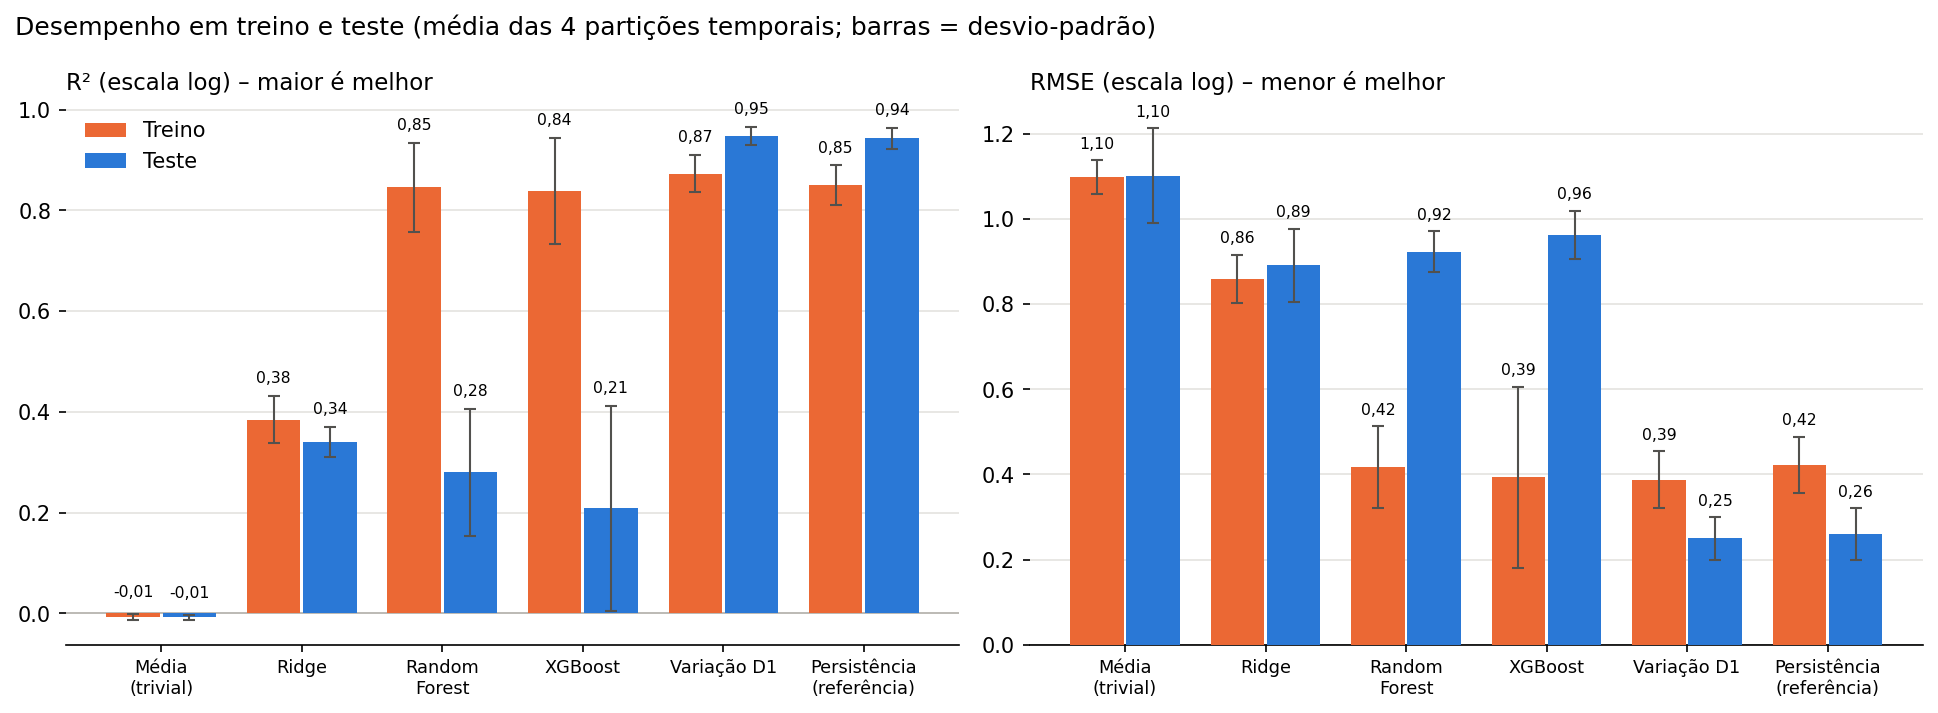

In [25]:
# Grafico 1: treino x teste (media das particoes), dois paineis com escalas proprias
COR_TREINO, COR_TESTE = "#eb6834", "#2a78d6"
rot = {"Nivel - Media (trivial)": "Média\n(trivial)", "Nivel - Ridge": "Ridge", "Nivel - RandomForest": "Random\nForest",
       "Nivel - XGBoost": "XGBoost", "Variacao D1": "Variação D1", "Persistencia (referencia)": "Persistência\n(referência)"}
sd = tt.groupby(["modelo", "conjunto"])[["R2_log", "RMSE_log"]].std().unstack("conjunto").reindex(ORDEM)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), dpi=150)
for ax, met, titulo in [(axes[0], "R2_log", "R² (escala log) – maior é melhor"),
                        (axes[1], "RMSE_log", "RMSE (escala log) – menor é melhor")]:
    x = np.arange(len(ORDEM)); w = 0.38
    for k, (conj, cor) in enumerate([("treino", COR_TREINO), ("teste", COR_TESTE)]):
        v = res_tt[(met, conj)].values; e = sd[(met, conj)].values
        xs = x + (k - 0.5) * (w + 0.02)
        ax.bar(xs, v, width=w, color=cor, label=conj.capitalize(), zorder=3)
        ax.errorbar(xs, v, yerr=e, fmt="none", ecolor="#52514e", elinewidth=1, capsize=3, zorder=4)
        for xi, vi, ei in zip(xs, v, np.nan_to_num(e)):
            ax.text(xi, max(vi, 0) + ei + 0.02, f"{vi:.2f}".replace(".", ","), ha="center", va="bottom", fontsize=7.5)
    ax.set_xticks(x); ax.set_xticklabels([rot[m] for m in ORDEM], fontsize=8.5)
    ax.axhline(0, color="#b5b3ad", lw=0.8)
    ax.set_title(titulo, loc="left", fontsize=11)
    ax.yaxis.grid(True, color="#e4e3df", lw=0.8); ax.set_axisbelow(True)
    for s in ["top", "right", "left"]: ax.spines[s].set_visible(False)
axes[0].legend(frameon=False, loc="upper left")
fig.suptitle("Desempenho em treino e teste (média das 4 partições temporais; barras = desvio-padrão)", x=0.01, ha="left", fontsize=12)
plt.tight_layout(); plt.savefig(f"{CKPT}/fig_treino_teste.png", dpi=200, bbox_inches="tight"); plt.show()

In [26]:
# Curvas de aprendizado na particao de 2025, com os hiperparametros ja escolhidos
ano_lc = max(ANOS)
tr_n, te_n = fold_idx[ano_lc]          # indices em `dados` (modelos de nivel)
tr_v, te_v = idx_var[ano_lc]           # indices em `mv` (modelo D1)
jog_treino = np.unique(grupos[tr_n])
FRACOES, REPETICOES = [0.2, 0.35, 0.5, 0.65, 0.8, 1.0], 8
rng_lc = np.random.default_rng(RANDOM_STATE)

MODELOS_LC = {"Ridge": ("nivel", modelos_treinados[("Ridge", ano_lc)]),
              "Random Forest": ("nivel", modelos_treinados[("RandomForest", ano_lc)]),
              "XGBoost": ("nivel", modelos_treinados[("XGBoost", ano_lc)]),
              "Variação D1": ("var", modelos_var[ano_lc])}
curvas = []
for frac in FRACOES:
    for rep in range(REPETICOES if frac < 1 else 1):
        jog = set(rng_lc.choice(jog_treino, max(5, int(round(frac * len(jog_treino)))), replace=False))
        sub_n = np.array([i for i in tr_n if grupos[i] in jog])
        sub_v = np.array([i for i in tr_v if gv[i] in jog])
        for nome, (tipo, base) in MODELOS_LC.items():
            mod = clone(base)
            if tipo == "nivel":
                mod.fit(X.iloc[sub_n], y.iloc[sub_n])
                mt = met_log(y.iloc[sub_n].values, mod.predict(X.iloc[sub_n]))
                me = met_log(y.iloc[te_n].values, mod.predict(X.iloc[te_n])); n_tr = len(sub_n)
            else:
                mod.fit(Xv.iloc[sub_v], mv["delta"].iloc[sub_v])
                mt = met_log(mv["y"].values[sub_v], mv["v_ant_log"].values[sub_v] + mod.predict(Xv.iloc[sub_v]))
                me = met_log(mv["y"].values[te_v], mv["v_ant_log"].values[te_v] + mod.predict(Xv.iloc[te_v])); n_tr = len(sub_v)
            for conj, m in [("treino", mt), ("teste", me)]:
                curvas.append({"modelo": nome, "fracao": frac, "rep": rep, "n_treino": n_tr, "conjunto": conj, **m})
curvas = pd.DataFrame(curvas)
persist_teste = met_log(mv["y"].values[te_v], mv["v_ant_log"].values[te_v])

resumo_lc = curvas.groupby(["modelo", "fracao", "conjunto"]).agg(
    n_treino=("n_treino", "mean"), R2=("R2_log", "mean"), RMSE=("RMSE_log", "mean"), RMSE_dp=("RMSE_log", "std")).reset_index()
print(f"particao de teste {ano_lc}: treino completo = {len(tr_n)} observacoes; teste = {len(te_n)}")
print(f"persistencia no teste: RMSE log {persist_teste['RMSE_log']:.3f} | R2 log {persist_teste['R2_log']:.3f}\n")
print(resumo_lc.pivot_table(index=["modelo", "fracao"], columns="conjunto", values=["R2", "RMSE"]).round(3).to_string())
curvas.to_csv(f"{CKPT}/curvas_aprendizado.csv", index=False)

particao de teste 2025: treino completo = 388 observacoes; teste = 286
persistencia no teste: RMSE log 0.283 | R2 log 0.947

                         R2          RMSE       
conjunto              teste treino  teste treino
modelo        fracao                            
Random Forest 0.20    0.194  0.894  1.106  0.354
              0.35    0.267  0.898  1.055  0.338
              0.50    0.292  0.896  1.037  0.346
              0.65    0.365  0.889  0.982  0.368
              0.80    0.385  0.877  0.967  0.386
              1.00    0.427  0.869  0.934  0.400
Ridge         0.20    0.250  0.492  1.067  0.778
              0.35    0.334  0.469  1.006  0.770
              0.50    0.328  0.443  1.011  0.801
              0.65    0.353  0.428  0.992  0.835
              0.80    0.358  0.418  0.988  0.841
              1.00    0.376  0.421  0.975  0.840
Variação D1   0.20    0.951  0.910  0.273  0.314
              0.35    0.953  0.889  0.267  0.347
              0.50    0.955  0.906  0.263 

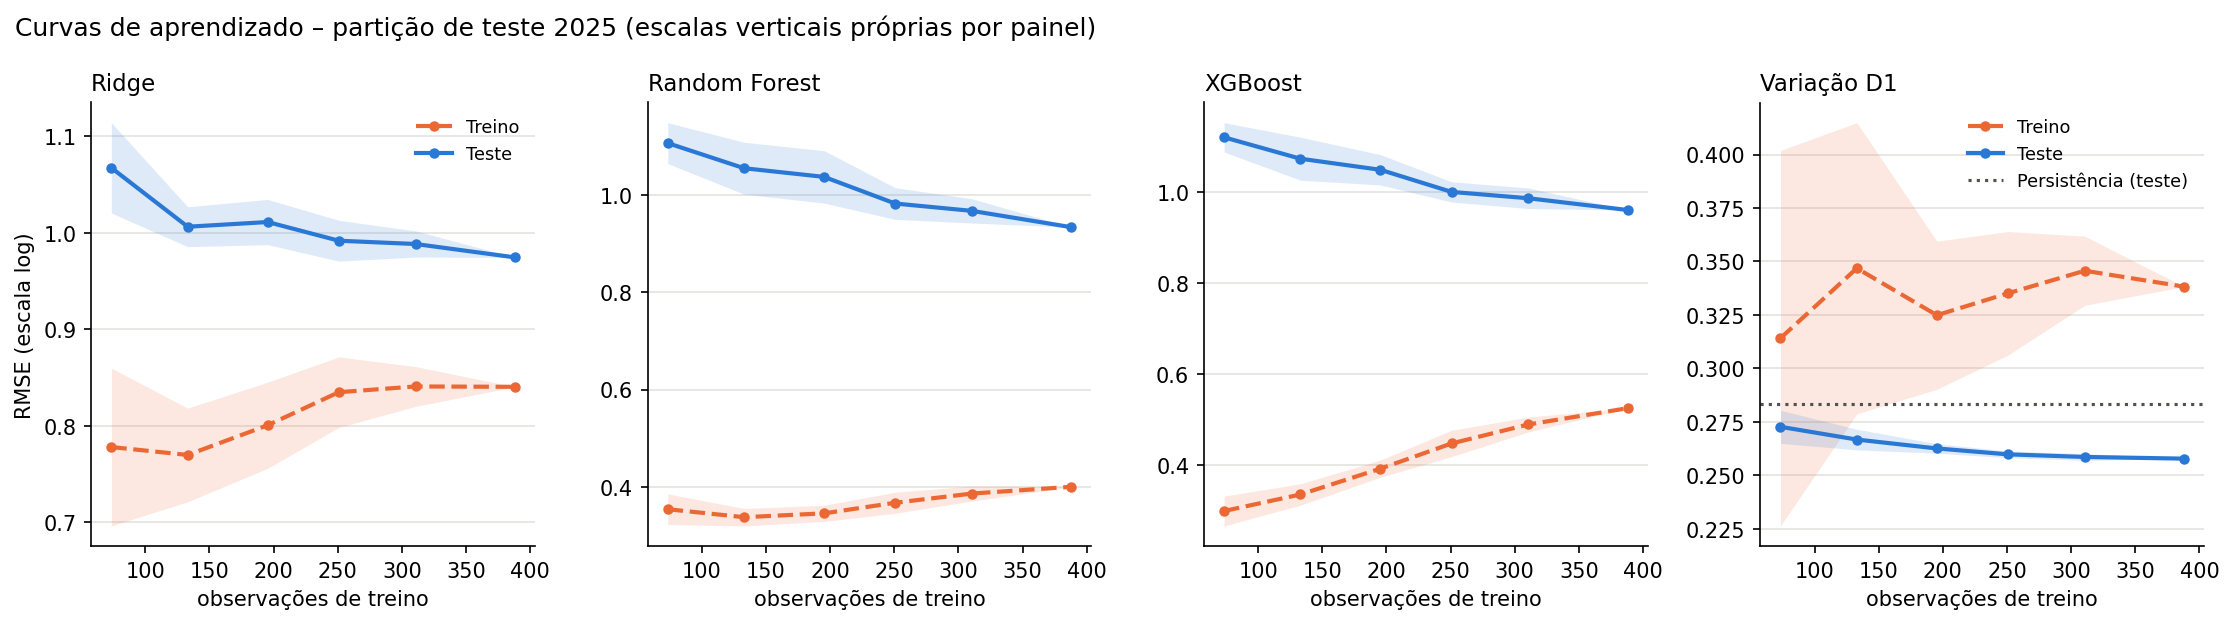

In [27]:
# Grafico 2: curvas de aprendizado (RMSE log); faixa = +-1 desvio-padrao entre sorteios
fig, axes = plt.subplots(1, 4, figsize=(15, 4.2), dpi=150)
for ax, nome in zip(axes, MODELOS_LC):
    d = resumo_lc[resumo_lc["modelo"] == nome]
    for conj, cor, est in [("treino", COR_TREINO, "--"), ("teste", COR_TESTE, "-")]:
        dd = d[d["conjunto"] == conj].sort_values("n_treino")
        ax.plot(dd["n_treino"], dd["RMSE"], est, color=cor, lw=2, marker="o", ms=4, label=conj.capitalize())
        ax.fill_between(dd["n_treino"], dd["RMSE"] - dd["RMSE_dp"].fillna(0), dd["RMSE"] + dd["RMSE_dp"].fillna(0),
                        color=cor, alpha=0.15, lw=0)
    if nome == "Variação D1":
        ax.axhline(persist_teste["RMSE_log"], color="#52514e", ls=":", lw=1.5, label="Persistência (teste)")
    ax.set_title(nome, loc="left", fontsize=11)
    ax.set_xlabel("observações de treino")
    ax.yaxis.grid(True, color="#e4e3df", lw=0.8); ax.set_axisbelow(True)
    for s in ["top", "right"]: ax.spines[s].set_visible(False)
axes[0].set_ylabel("RMSE (escala log)")
axes[0].legend(frameon=False, fontsize=8.5); axes[-1].legend(frameon=False, fontsize=8.5)
fig.suptitle(f"Curvas de aprendizado – partição de teste {ano_lc} (escalas verticais próprias por painel)", x=0.01, ha="left", fontsize=12)
plt.tight_layout(); plt.savefig(f"{CKPT}/fig_curvas_aprendizado.png", dpi=200, bbox_inches="tight"); plt.show()

> **Como ler.** Treino muito melhor que teste indica sobreajuste (o modelo decora o treino).
> Na curva de aprendizado, se a linha de teste ainda desce no fim, mais dados ajudariam; se ja
> estabilizou, o limite esta nas variaveis, nao no tamanho da amostra. Para o D1, o que importa
> e a distancia da linha de teste para a persistencia.

---
## Secao 5 - Amostra 2: exportacoes para a Europa

O modelo principal (D1) parte do ultimo valor publicado antes do corte da temporada de
referencia e soma a variacao prevista pelo desempenho. A temporada de referencia e sempre a
ultima **concluida** antes da venda (calendario de abril a dezembro).

As variaveis vem de `dados_full`, e nao de `dados`: os jogadores vendidos costumam nao ter
valor-alvo valido como atletas do Brasileirao, e exigir o alvo eliminaria justamente eles.

In [28]:
transfers = pd.read_csv(f"{DADOS}/transfers.csv")
clubs = pd.read_csv(f"{DADOS}/clubs.csv", usecols=["club_id","domestic_competition_id"])
comps = pd.read_csv(f"{DADOS}/competitions.csv", usecols=["competition_id","confederation"])

transfers["transfer_date"] = pd.to_datetime(transfers["transfer_date"])
liga = clubs.set_index("club_id")["domestic_competition_id"].to_dict()
conf = comps.set_index("competition_id")["confederation"].to_dict()
transfers["liga_origem"]  = transfers["from_club_id"].map(liga)
transfers["liga_destino"] = transfers["to_club_id"].map(liga)
transfers["conf_destino"] = transfers["liga_destino"].map(conf)

exportacoes = transfers[
    (transfers["liga_origem"]=="BRA1") &
    (transfers["conf_destino"]=="europa") &
    (transfers["transfer_fee"].notna()) & (transfers["transfer_fee"]>0) &
    (transfers["transfer_date"] >= "2021-01-01")
].copy()

# CORRECAO: sempre a ultima temporada CONCLUIDA (calendario abril-dezembro)
exportacoes["temporada_ref"] = exportacoes["transfer_date"].dt.year - 1

print("exportacoes BRA1 -> Europa:", len(exportacoes))
print(exportacoes.groupby(exportacoes["transfer_date"].dt.year).size().to_string())

exportacoes BRA1 -> Europa: 149
transfer_date
2021    15
2022    24
2023    26
2024    31
2025    43
2026    10


In [29]:
# Valor anterior ao corte da temporada de referencia, para cada exportacao
exp = exportacoes[exportacoes["temporada_ref"].isin(list(modelos_var))].copy()
exp["corte_ref"] = pd.to_datetime(exp["temporada_ref"].astype(str) + "-12-31")
va = val_c.rename(columns={"market_value_in_eur":"v_ant","date":"d_ant"})[["player_id","v_ant","d_ant"]]
exp = exp.merge(va, on="player_id")
exp = (exp[exp["d_ant"] < exp["corte_ref"]].sort_values("d_ant")
         .groupby(["player_id","transfer_date"]).last().reset_index())

feats = dados_full[["player_id","temporada"] + DES + CAT_COMPLETA]
aplicacao = exp.merge(feats, left_on=["player_id","temporada_ref"],
                      right_on=["player_id","temporada"], how="inner")

partes = []
for ano, grupo in aplicacao.groupby("temporada_ref"):
    g = grupo.copy()
    g["delta_prev"]     = modelos_var[ano].predict(g[DES + CAT_COMPLETA])
    g["valor_estimado"] = np.expm1(np.log1p(g["v_ant"]) + g["delta_prev"])
    partes.append(g)
aplicacao = pd.concat(partes, ignore_index=True)
aplicacao["premio_relativo"] = aplicacao["transfer_fee"] / aplicacao["valor_estimado"] - 1

print(f"exportacoes avaliadas: {len(aplicacao)}")
print("\n=== MEDIANAS ===")
print(f"taxa paga / estimativa do modelo D1      : {(aplicacao.transfer_fee/aplicacao.valor_estimado).median():.2f}")
print(f"taxa paga / valor anterior ao corte      : {(aplicacao.transfer_fee/aplicacao.v_ant).median():.2f}")
print(f"taxa paga / valor Transfermarkt na venda : {(aplicacao.transfer_fee/aplicacao.market_value_in_eur).median():.2f}")
print(f"estimativa D1 / valor anterior           : {(aplicacao.valor_estimado/aplicacao.v_ant).median():.2f}")

q = aplicacao["premio_relativo"].quantile([.25,.5,.75])
print(f"\npremio relativo: P25 {q[.25]:+.0%} | mediana {q[.5]:+.0%} | P75 {q[.75]:+.0%}")
print(f"vendas acima da estimativa: {(aplicacao.premio_relativo > 0).mean():.0%}")
# Qual referencia fica mais perto da taxa paga? Erro em log (simetrico: x2 e /2 pesam igual)
from scipy.stats import wilcoxon as _wx
print("\n=== distancia ate a taxa paga (|log taxa/referencia|) ===")
errs = {}
for rot, col in [("estimativa D1", "valor_estimado"), ("valor anterior ao corte", "v_ant"),
                 ("valor TM na data da venda", "market_value_in_eur")]:
    e = np.abs(np.log(aplicacao["transfer_fee"] / aplicacao[col])); errs[rot] = e
    print(f"{rot:26s}: mediana {e.median():.3f} | dentro de x/÷1,5: {(e <= np.log(1.5)).mean():.0%}")
print(f"estimativa D1 x valor anterior: Wilcoxon p = {_wx(errs['estimativa D1'], errs['valor anterior ao corte']).pvalue:.3f}")

# Sensibilidade: taxa muito abaixo do valor TM na venda sugere emprestimo ou cessao parcial
susp = aplicacao["transfer_fee"] < 0.25 * aplicacao["market_value_in_eur"]
a2 = aplicacao[~susp]
print(f"\nsensibilidade: {susp.sum()} vendas com taxa < 25% do valor TM na venda (possivel emprestimo)")
print(f"  sem elas (n={len(a2)}): taxa/estimativa {(a2.transfer_fee/a2.valor_estimado).median():.2f} | "
      f"premio P25 {(a2.premio_relativo.quantile(.25)):+.0%} | mediana {a2.premio_relativo.median():+.0%} | "
      f"P75 {a2.premio_relativo.quantile(.75):+.0%}")
aplicacao.to_parquet(f"{CKPT}/aplicacao_d1.parquet")

exportacoes avaliadas: 50

=== MEDIANAS ===
taxa paga / estimativa do modelo D1      : 1.03
taxa paga / valor anterior ao corte      : 1.25
taxa paga / valor Transfermarkt na venda : 1.09
estimativa D1 / valor anterior           : 1.15

premio relativo: P25 -29% | mediana +3% | P75 +54%
vendas acima da estimativa: 50%

=== distancia ate a taxa paga (|log taxa/referencia|) ===
estimativa D1             : mediana 0.364 | dentro de x/÷1,5: 54%
valor anterior ao corte   : mediana 0.354 | dentro de x/÷1,5: 56%
valor TM na data da venda : mediana 0.405 | dentro de x/÷1,5: 54%
estimativa D1 x valor anterior: Wilcoxon p = 0.404

sensibilidade: 2 vendas com taxa < 25% do valor TM na venda (possivel emprestimo)
  sem elas (n=48): taxa/estimativa 1.09 | premio P25 -25% | mediana +9% | P75 +61%


### Funil da amostra de aplicacao

Conta, etapa por etapa, por que parte das exportacoes nao entra na avaliacao. Nao altera nenhum
resultado; serve para a tabela de dados do artigo.

In [30]:
f0 = exportacoes.copy()
anos_teste = sorted(modelos_var)
f1 = f0[f0["temporada_ref"].isin(anos_teste)]
chaves = set(zip(dados_full["player_id"], dados_full["temporada"]))
f2 = f1[[k in chaves for k in zip(f1["player_id"], f1["temporada_ref"])]]
corte_f = pd.to_datetime(f2["temporada_ref"].astype(str) + "-12-31")
tem_ant = [((val_c["player_id"] == pid) & (val_c["date"] < c)).any()
           for pid, c in zip(f2["player_id"], corte_f)]
f3 = f2[tem_ant]

funil = pd.DataFrame([
    ("Exportacoes BRA1 -> Europa com taxa > 0 (2021 em diante)",                      len(f0)),
    (f"  temporada de referencia com modelo de teste ({anos_teste[0]}-{anos_teste[-1]})", len(f1)),
    ("  jogador pareado Cartola-Transfermarkt na temporada de referencia",            len(f2)),
    ("  com valor de mercado anterior ao corte",                                       len(f3)),
    ("Avaliadas (apos remover duplicidades jogador-data)",                             len(aplicacao)),
], columns=["etapa", "n"])
print(funil.to_string(index=False))
print("\nexcluidas por temporada de referencia sem modelo de teste, por ano da venda:")
print(f0[~f0["temporada_ref"].isin(anos_teste)].groupby(f0["transfer_date"].dt.year).size().to_string())
funil.to_csv(f"{CKPT}/funil_exportacoes.csv", index=False)

                                                             etapa   n
          Exportacoes BRA1 -> Europa com taxa > 0 (2021 em diante) 149
           temporada de referencia com modelo de teste (2022-2025) 110
  jogador pareado Cartola-Transfermarkt na temporada de referencia  50
                            com valor de mercado anterior ao corte  50
                Avaliadas (apos remover duplicidades jogador-data)  50

excluidas por temporada de referencia sem modelo de teste, por ano da venda:
transfer_date
2021    15
2022    24


> **Como ler.** Com o modelo D1, a estimativa ja parte do valor de mercado anterior; por isso,
> comparar a taxa paga com o modelo fica proximo de compara-la com o proprio Transfermarkt.
> A razao `estimativa D1 / valor anterior` mostra quanto o desempenho deslocou a estimativa.
>
> O premio relativo nao prova subvalorizacao nem exploracao: a taxa incorpora contrato,
> urgencia, reputacao e direitos economicos, que o modelo nao observa. A amostra de aplicacao e
> pequena por natureza e deve ser apresentada com a incerteza correspondente.

---
## Secao 6 - SO2: estratificacao do erro

Decompoe o erro do modelo principal (D1) por trajetoria, posicao e faixa de valor, sempre ao
lado do erro da persistencia - a pergunta passa a ser **em que grupos o desempenho acrescenta
informacao ao valor anterior**. A trajetoria usa apenas o historico anterior ao corte, e o
historico serve para classificar, nunca como entrada do modelo.

In [31]:
MODELO_ESCOLHIDO = PRINCIPAL_VAR
print("modelo principal:", MODELO_ESCOLHIDO)

aval = mv.copy()
aval["pred"] = pred_var[PRINCIPAL_VAR]
aval = aval[aval["pred"].notna()].copy()
aval["real_log"] = aval["y"]
aval["res_log"]  = aval["pred"] - aval["real_log"]         # >0 = superestimou
aval["est_eur"]  = np.expm1(aval["pred"])
aval["erro_log_modelo"]  = aval["res_log"].abs()
aval["erro_log_persist"] = (aval["v_ant_log"] - aval["real_log"]).abs()
print("observacoes avaliadas:", len(aval))

modelo principal: D1 variacao, desempenho
observacoes avaliadas: 882


In [32]:
# Indicadores de trajetoria, so com historico anterior ao corte
hist = {k: v for k, v in valuations.groupby("player_id")}

def indicadores(pid, corte, janela_anos=3, min_obs=4):
    h = hist.get(pid)
    if h is None:
        return pd.Series({"incl": np.nan, "vol": np.nan, "queda": np.nan, "n_obs": 0})
    h = h[(h["date"] < corte) & (h["date"] >= corte - pd.DateOffset(years=janela_anos))].sort_values("date")
    if len(h) < min_obs:
        return pd.Series({"incl": np.nan, "vol": np.nan, "queda": np.nan, "n_obs": len(h)})
    t  = (h["date"] - h["date"].min()).dt.days.values / 365.25
    lv = np.log(h["market_value_in_eur"].values.astype(float))
    v  = h["market_value_in_eur"].values.astype(float)
    pico = np.maximum.accumulate(v)
    return pd.Series({
        "incl":  np.polyfit(t, lv, 1)[0] if np.ptp(t) > 0 else 0.0,   # log-euros por ano
        "vol":   np.std(np.diff(lv), ddof=1) if len(lv) > 1 else 0.0, # diferencas em log
        "queda": float(np.max((pico - v) / pico)),                    # maior queda relativa
        "n_obs": len(h)})

aval = pd.concat([aval, aval.apply(lambda r: indicadores(r["player_id"], r["corte"]), axis=1)], axis=1)
print("percentis dos indicadores (para calibrar os limiares):")
print(aval[["incl","vol","queda"]].quantile([.10,.25,.50,.75,.90]).round(3).to_string())

percentis dos indicadores (para calibrar os limiares):
       incl    vol  queda
0.10 -0.391  0.087  0.000
0.25 -0.204  0.123  0.000
0.50  0.085  0.193  0.250
0.75  0.467  0.310  0.500
0.90  1.119  0.555  0.667


> **Calibrar antes de olhar o erro.** Os limiares abaixo vieram do documento de pre-registro.
> Se a distribuicao ficar desequilibrada, recalibre **pelos percentis acima**, registre a nova
> versao datada do documento e nao mexa mais depois de ver o erro por grupo. Ajustar o
> instrumento pela distribuicao e legitimo; ajusta-lo pelo resultado nao e.

### Limiares: o que muda na distribuicao

O grupo volatil concentra metade da amostra com os limiares atuais, e o meteorico ficou com 25
casos, abaixo do minimo de 30. A celula abaixo mostra como a distribuicao responde a limiares
alternativos, definidos pelos percentis observados (P75 = 0,315 para volatilidade e 0,50 para
queda; P90 = 0,569 e 0,667). **Escolha olhando so a distribuicao**, nunca o erro por grupo.

In [33]:
# Efeito de limiares alternativos SOBRE A DISTRIBUICAO (nao sobre o erro).
# Serve para escolher com o orientador; registrar a versao escolhida no documento congelado.
for lv, lq in [(0.40,0.35), (0.32,0.50), (0.40,0.50), (0.57,0.67)]:
    tmp = np.where(aval["incl"].isna(), "SEM_HISTORICO",
          np.where((aval["vol"]>=lv) | (aval["queda"]>=lq), "VOLATIL",
          np.where(aval["incl"]>=0.15, "ASCENSAO", "ESTAGNACAO_DECLINIO")))
    d_ = pd.Series(tmp).value_counts()
    print(f"vol>={lv:.2f} ou queda>={lq:.2f} -> " +
          " | ".join(f"{k}={v}" for k, v in d_.items()))

vol>=0.40 ou queda>=0.35 -> VOLATIL=444 | ASCENSAO=223 | ESTAGNACAO_DECLINIO=161 | SEM_HISTORICO=54
vol>=0.32 ou queda>=0.50 -> VOLATIL=406 | ESTAGNACAO_DECLINIO=236 | ASCENSAO=186 | SEM_HISTORICO=54
vol>=0.40 ou queda>=0.50 -> VOLATIL=361 | ESTAGNACAO_DECLINIO=238 | ASCENSAO=229 | SEM_HISTORICO=54
vol>=0.57 ou queda>=0.67 -> ESTAGNACAO_DECLINIO=380 | ASCENSAO=291 | VOLATIL=157 | SEM_HISTORICO=54


In [34]:
# Conjuntos de limiares. A escolha deve ser feita olhando APENAS a distribuicao
# (celula anterior), nunca o erro por grupo, e registrada em nova versao datada do
# documento de pre-registro.
#   "original"    : documento congelado      -> volatil = 50% da amostra
#   "recomendado" : queda >= P75 (0,50)      -> tres grupos com tamanhos semelhantes
LIMIARES = {
    "original":    {"vol": 0.40, "queda": 0.35},
    "recomendado": {"vol": 0.40, "queda": 0.50},
}
ESCOLHA_LIMIAR = "recomendado"          # versao 2 do pre-registro (13/10/2026)

LIM_VOL   = LIMIARES[ESCOLHA_LIMIAR]["vol"]
LIM_QUEDA = LIMIARES[ESCOLHA_LIMIAR]["queda"]
LIM_GRADUAL = 0.15
print(f"limiares em uso ({ESCOLHA_LIMIAR}): volatilidade >= {LIM_VOL} ou queda >= {LIM_QUEDA}")

def classificar(r):
    if pd.isna(r["incl"]):                                  return "SEM_HISTORICO"
    if r["vol"] >= LIM_VOL or r["queda"] >= LIM_QUEDA:      return "VOLATIL"
    if r["incl"] >= LIM_GRADUAL:                            return "ASCENSAO"
    return "ESTAGNACAO_DECLINIO"

aval["grupo"] = aval.apply(classificar, axis=1)
dist = aval["grupo"].value_counts()
print(dist.to_string())
print("\nproporcao:"); print((dist / len(aval)).round(3).to_string())
if (dist < 30).any():
    print("\n*** ha grupo com menos de 30 casos ***")

limiares em uso (recomendado): volatilidade >= 0.4 ou queda >= 0.5
grupo
VOLATIL                361
ESTAGNACAO_DECLINIO    238
ASCENSAO               229
SEM_HISTORICO           54

proporcao:
grupo
VOLATIL                0.409
ESTAGNACAO_DECLINIO    0.270
ASCENSAO               0.260
SEM_HISTORICO          0.061


In [35]:
def por_grupo(df, col):
    return (df.groupby(col, observed=True)
              .apply(lambda s: pd.Series({
                  "n": len(s),
                  "MAE_eur": mean_absolute_error(s["market_value_in_eur"], s["est_eur"]),
                  "MAE_eur_persist": mean_absolute_error(s["market_value_in_eur"], s["v_ant"]),
                  "vies_log": s["res_log"].mean(),
                  "erro_log_medio": s["erro_log_modelo"].mean(),
                  "erro_log_persist": s["erro_log_persist"].mean(),
                  "modelo_melhor_pct": (s["erro_log_modelo"] < s["erro_log_persist"]).mean() * 100}),
                  include_groups=False)
              .sort_values("n", ascending=False).round(3))

aval["faixa_valor"] = pd.qcut(aval["market_value_in_eur"], 4,
                              labels=["baixo","medio-baixo","medio-alto","alto"], duplicates="drop")
tabelas_estrat = {}
for col in ["grupo", "posicao", "faixa_valor"]:
    t = por_grupo(aval, col); tabelas_estrat[col] = t
    print(f"\n=== por {col} ===")
    print(t.to_string())
    t.to_csv(f"{CKPT}/estratificacao_{col}.csv")


=== por grupo ===
                         n     MAE_eur  MAE_eur_persist  vies_log  erro_log_medio  erro_log_persist  modelo_melhor_pct
grupo                                                                                                                 
VOLATIL              361.0  501622.206       406440.443     0.031           0.147             0.151             45.983
ESTAGNACAO_DECLINIO  238.0  502954.106       454726.891     0.041           0.147             0.136             39.496
ASCENSAO             229.0  661582.405       583406.114     0.012           0.137             0.118             34.498
SEM_HISTORICO         54.0  700279.238       593518.519    -0.201           0.415             0.408             50.000

=== por posicao ===
              n     MAE_eur  MAE_eur_persist  vies_log  erro_log_medio  erro_log_persist  modelo_melhor_pct
posicao                                                                                                    
meia      300.0  587147.711   

### Apendice: as duas versoes dos limiares

Exigencia do pre-registro: quando os limiares mudam, as duas versoes sao reportadas. A versao 1
(original) deixava metade da amostra no grupo volatil; a versao 2 (13/10/2026) usa o P75 da
queda maxima (0,50). A conclusao sobre vies por grupo so e robusta se valer nas duas.

In [36]:
comp_lim = {}
for nome_l, L in LIMIARES.items():
    a_ = aval.copy()
    a_["grupo"] = np.where(a_["incl"].isna(), "SEM_HISTORICO",
                  np.where((a_["vol"] >= L["vol"]) | (a_["queda"] >= L["queda"]), "VOLATIL",
                  np.where(a_["incl"] >= LIM_GRADUAL, "ASCENSAO", "ESTAGNACAO_DECLINIO")))
    t = por_grupo(a_, "grupo"); comp_lim[nome_l] = t
    t.to_csv(f"{CKPT}/estratificacao_grupo_limiar_{nome_l}.csv")

cols_l = ["n", "vies_log", "erro_log_medio", "erro_log_persist", "modelo_melhor_pct"]
lado = pd.concat({k: v[cols_l] for k, v in comp_lim.items()}, axis=1)
print(lado.to_string())

print("\nconferencia: |vies| < 0,05 em todos os grupos com historico?")
for k, v in comp_lim.items():
    com_hist = v.drop(index="SEM_HISTORICO", errors="ignore")
    print(f"  {k:12s}: {'sim' if (com_hist['vies_log'].abs() < 0.05).all() else 'NAO'} "
          f"(maior |vies| = {com_hist['vies_log'].abs().max():.3f})")

                    original                                                            recomendado                                                           
                           n vies_log erro_log_medio erro_log_persist modelo_melhor_pct           n vies_log erro_log_medio erro_log_persist modelo_melhor_pct
grupo                                                                                                                                                         
VOLATIL                444.0    0.037          0.148            0.152            45.946       361.0    0.031          0.147            0.151            45.983
ASCENSAO               223.0    0.009          0.137            0.118            34.529       229.0    0.012          0.137            0.118            34.498
ESTAGNACAO_DECLINIO    161.0    0.035          0.144            0.124            36.025       238.0    0.041          0.147            0.136            39.496
SEM_HISTORICO           54.0   -0.201         

> **Leitura.** `modelo_melhor_pct` e a proporcao de casos em que o modelo erra menos que a
> persistencia. Valores acima de 50% indicam grupos em que o desempenho acrescenta informacao ao
> valor anterior. Como parte dos valores nao muda entre registros (e ali a persistencia acerta
> exatamente), espere proporcoes moderadas mesmo nos grupos em que o modelo ajuda.

---
## Secao 7 - SO4: interpretabilidade por posicao

Com o modelo D1, os valores SHAP explicam a **variacao prevista** do valor de mercado: quais
aspectos do desempenho levam o modelo a esperar valorizacao ou desvalorizacao. Como o modelo e
linear, usa-se o `LinearExplainer`.

Com a especificacao enxuta, as variaveis de desempenho nao sao mais redundantes entre si, de
modo que o sinal de cada coeficiente pode ser lido como o sentido do efeito. Na versao completa
isso nao era possivel: "assistencias por jogo" aparecia com efeito negativo apenas por dividir a
informacao com o total de assistencias.

ajuste=311 calibracao=77 teste=286

10 variaveis mais influentes na VARIACAO prevista (media do |SHAP|):
num__idade_no_corte          0.0752
num__DS                      0.0241
num__G                       0.0219
num__FC                      0.0139
num__pontos                  0.0114
cat__posicao_desconhecido    0.0068
cat__posicao_meia            0.0057
cat__foot_left               0.0051
cat__foot_right              0.0047
num__A                       0.0045

sentido do efeito das 10 principais:
num__idade_no_corte         -0.0784
num__DS                      0.0386
num__G                       0.0305
num__FC                     -0.0211
num__pontos                  0.0122
cat__posicao_desconhecido    0.0270
cat__posicao_meia           -0.0146
cat__foot_left               0.0121
cat__foot_right             -0.0108
num__A                      -0.0054


/tmp/ipykernel_1768/1012219339.py:35: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_values, Xt, feature_names=nomes_feat, show=False)


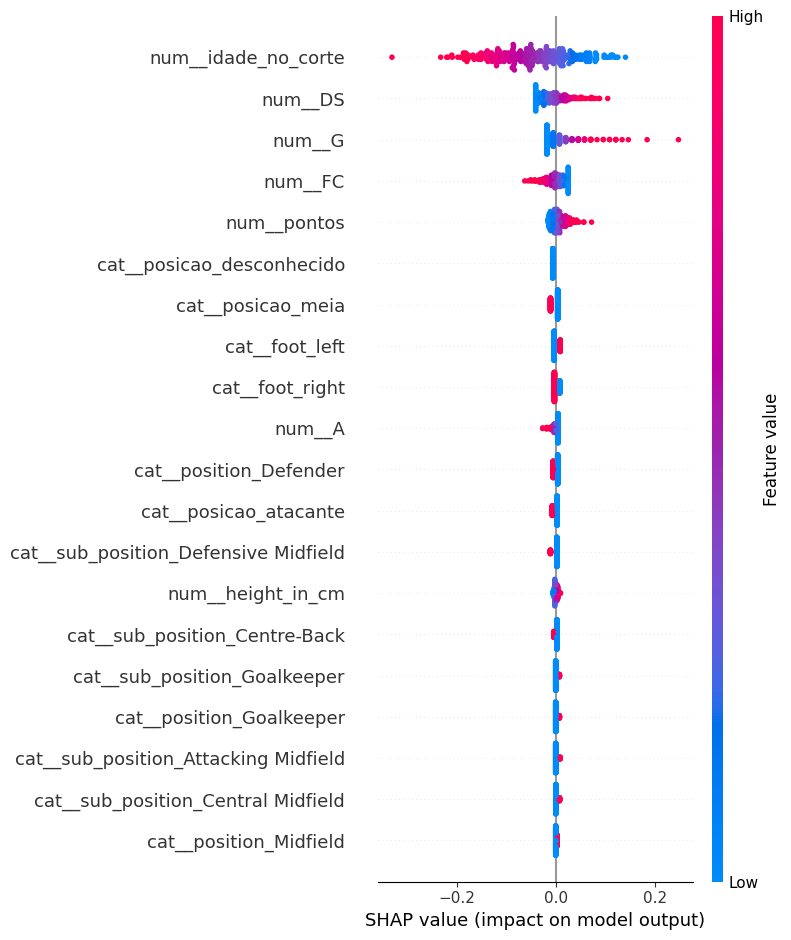

In [37]:
!pip install shap -q
import shap

ANO_FINAL = max(modelos_var)
tr_f, te_f = idx_var[ANO_FINAL]

# Reserva de calibracao para a Secao 8: o modelo nao pode ver estes dados
n_cal   = max(50, len(tr_f)//5)
idx_cal = tr_f[-n_cal:]
idx_fit = tr_f[:-n_cal]
print(f"ajuste={len(idx_fit)} calibracao={len(idx_cal)} teste={len(te_f)}")

busca = RandomizedSearchCV(Pipeline([("p",pre_var),("m",Ridge())]), {"m__alpha": np.logspace(-2,4,25)},
                           n_iter=25, cv=3, random_state=RANDOM_STATE, n_jobs=-1)
modelo_final = busca.fit(Xv.iloc[idx_fit], mv["delta"].iloc[idx_fit]).best_estimator_

prep = modelo_final.named_steps["p"]
Xt, Xf = prep.transform(Xv.iloc[te_f]), prep.transform(Xv.iloc[idx_fit])
if hasattr(Xt, "toarray"): Xt, Xf = Xt.toarray(), Xf.toarray()
nomes_feat = prep.get_feature_names_out()

explainer = shap.LinearExplainer(modelo_final.named_steps["m"],
                                 shap.maskers.Independent(Xf, max_samples=len(Xf)))
shap_values = explainer.shap_values(Xt)

importancia = pd.Series(np.abs(shap_values).mean(0), index=nomes_feat).sort_values(ascending=False)
print("\n10 variaveis mais influentes na VARIACAO prevista (media do |SHAP|):")
print(importancia.head(10).round(4).to_string())

# Sentido do efeito: coeficiente padronizado (positivo = empurra para valorizacao)
coef = pd.Series(modelo_final.named_steps["m"].coef_, index=nomes_feat)
print("\nsentido do efeito das 10 principais:")
print(coef[importancia.head(10).index].round(4).to_string())
importancia.to_csv(f"{CKPT}/shap_importancia.csv")
shap.summary_plot(shap_values, Xt, feature_names=nomes_feat, show=False)
import matplotlib.pyplot as plt
plt.tight_layout(); plt.savefig(f"{CKPT}/shap_resumo.png", dpi=200, bbox_inches="tight"); plt.show()

In [38]:
posicoes = mv.iloc[te_f]["posicao"].values
for pos in pd.Series(posicoes).value_counts().index:
    m_ = posicoes == pos
    if m_.sum() < 20:
        print(f"(pulando {pos}: n={m_.sum()})"); continue
    top = (pd.Series(np.abs(shap_values[m_]).mean(0), index=nomes_feat)
             .sort_values(ascending=False).head(6))
    print(f"\n=== {pos} (n={m_.sum()}) ===")
    print(top.round(4).to_string())


=== meia (n=88) ===
num__idade_no_corte    0.0750
num__DS                0.0215
num__G                 0.0163
num__FC                0.0147
cat__posicao_meia      0.0114
num__pontos            0.0087

=== atacante (n=72) ===
num__idade_no_corte      0.0710
num__G                   0.0378
num__DS                  0.0248
num__FC                  0.0140
num__pontos              0.0132
cat__posicao_atacante    0.0077

=== lateral (n=55) ===
num__idade_no_corte          0.0746
num__DS                      0.0256
num__G                       0.0186
num__pontos                  0.0135
num__FC                      0.0126
cat__posicao_desconhecido    0.0068

=== zagueiro (n=49) ===
num__idade_no_corte          0.0692
num__DS                      0.0186
num__G                       0.0139
num__FC                      0.0091
num__pontos                  0.0087
cat__posicao_desconhecido    0.0068

=== goleiro (n=22) ===
num__idade_no_corte          0.1047
num__DS                      0.0412
num__

---
## Secao 8 - SO5: predicao conforme

*Split conformal* sobre o modelo D1. Os residuos da calibracao sao medidos na variacao, o que
equivale ao residuo do valor reconstruido em escala logaritmica. O intervalo e centrado no valor
anterior mais a variacao prevista.

In [39]:
CONFIANCA = 0.90

res_cal = np.abs(mv["delta"].values[idx_cal] - modelo_final.predict(Xv.iloc[idx_cal]))
n = len(res_cal)
q = np.quantile(res_cal, min(1.0, np.ceil((n + 1) * CONFIANCA) / n))

centro   = mv["v_ant_log"].values[te_f] + modelo_final.predict(Xv.iloc[te_f])
inferior = np.expm1(centro - q)
superior = np.expm1(centro + q)
real     = mv["market_value_in_eur"].values[te_f]

dentro  = (real >= inferior) & (real <= superior)
largura = np.median(superior - inferior)
print(f"confianca nominal : {CONFIANCA:.0%}")
print(f"cobertura obtida  : {dentro.mean():.1%}")
print(f"largura mediana   : EUR {largura:,.0f}")
print(f"largura / mediana do valor real: {largura/np.median(real):.2f}x")
print(f"leitura pratica: multiplicar e dividir a estimativa por {np.exp(q):.2f}")
print("\n(referencia, modelo de nivel da v12: cobertura 96,9%, largura 6,9x, fator 7,1)")

confianca nominal : 90%
cobertura obtida  : 95.1%
largura mediana   : EUR 2,202,205
largura / mediana do valor real: 1.10x
leitura pratica: multiplicar e dividir a estimativa por 1.67

(referencia, modelo de nivel da v12: cobertura 96,9%, largura 6,9x, fator 7,1)


> **Cobertura e largura andam juntas.** Compare com o modelo de nivel: la, o intervalo equivalia
> a multiplicar e dividir a estimativa por cerca de 7. Com o modelo D1, ancorado no valor
> anterior, o intervalo deve ficar muitas vezes mais estreito - e passar a ter utilidade pratica.

---
## Secao 9 - Casos individuais: o modelo aplicado a jogadores reais

Mostra, jogador a jogador, o que o modelo D1 faz na particao de teste mais recente:

1. parte do **ultimo valor publicado** pelo Transfermarkt antes do corte da temporada;
2. preve a **variacao** a partir do desempenho no Brasileirao (Cartola);
3. reconstroi a **estimativa** e o **intervalo de 90%** (Secao 8);
4. compara com o **valor publicado depois** e com a persistencia;
5. decompoe a variacao prevista nas contribuicoes de cada variavel (SHAP da Secao 7).

**Os casos nao sao escolhidos a mao.** Cada um sai de uma regra fixa, escrita antes de ver os
nomes (maior alta prevista que se confirmou, maior queda prevista que se confirmou, caso tipico,
valor nao revisado, maior erro). Uma amostra aleatoria com semente fixa vem logo depois, para
mostrar que os exemplos nao foram selecionados por serem favoraveis.

As contribuicoes sao medidas em relacao a um **jogador medio do conjunto de treino** e se
**multiplicam** (o modelo trabalha em log): +10% e -5% resultam em cerca de +4,5%, nao +5%.

In [40]:
# Casos individuais - particao de teste mais recente (mesmos objetos das Secoes 7 e 8)
jog = pd.read_csv(f"{DADOS}/players.csv", usecols=["player_id","name"])
nome_de = jog.set_index("player_id")["name"].to_dict()

ROTULO = {"num__idade_no_corte":"idade", "num__jogos":"jogos", "num__pontos":"pontos no Cartola",
          "num__G":"gols", "num__A":"assistencias", "num__DS":"desarmes",
          "num__FS":"faltas sofridas", "num__FC":"faltas cometidas", "num__height_in_cm":"altura"}
def rotulo(f):
    return ROTULO.get(f, f.replace("cat__", "").replace("_", " = ", 1))

# Intervalo conformal recalculado aqui (a variavel q e reutilizada em outras celulas)
n_c    = len(res_cal)
q_conf = np.quantile(res_cal, min(1.0, np.ceil((n_c + 1) * CONFIANCA) / n_c))

delta_prev = modelo_final.predict(Xv.iloc[te_f])
base_shap  = float(np.ravel(explainer.expected_value)[0])
# conferencia: ponto de partida + soma das contribuicoes = variacao prevista
assert np.allclose(base_shap + shap_values.sum(1), delta_prev, atol=1e-6), "SHAP nao fecha com a predicao"

cols = ["player_id","temporada","posicao","idade_no_corte","jogos","pontos","G","A","DS","FC",
        "v_ant","d_ant","market_value_in_eur","data_alvo","delta","v_ant_log"]
casos = mv.iloc[te_f][cols].copy()
casos["linha_shap"] = np.arange(len(te_f))
casos["nome"]       = casos["player_id"].map(nome_de).fillna("(sem nome)")
casos["delta_prev"] = delta_prev
casos["estimativa"] = np.expm1(casos["v_ant_log"] + delta_prev)
casos["inf90"]      = np.expm1(casos["v_ant_log"] + delta_prev - q_conf)
casos["sup90"]      = np.expm1(casos["v_ant_log"] + delta_prev + q_conf)
casos["erro_log"]   = (casos["v_ant_log"] + delta_prev) - np.log1p(casos["market_value_in_eur"])
casos["mudou"]      = casos["delta"].abs() > 0.01
casos["acertou_sentido"] = np.sign(casos["delta_prev"]) == np.sign(casos["delta"])
for c in ["d_ant","data_alvo"]:
    casos[c] = pd.to_datetime(casos[c], errors="coerce")

# Regras fixas de selecao
alta  = casos[casos.mudou & casos.acertou_sentido & (casos.delta > 0)]
queda = casos[casos.mudou & casos.acertou_sentido & (casos.delta < 0)]
fixo  = casos[~casos.mudou]
med   = casos["erro_log"].abs().median()
REGRAS = {
    "A) Maior ALTA prevista que se confirmou":          alta["delta_prev"].idxmax(),
    "B) Maior QUEDA prevista que se confirmou":         queda["delta_prev"].idxmin(),
    "C) Caso tipico (erro do modelo igual a mediana)":  (casos["erro_log"].abs() - med).abs().idxmin(),
    "D) Valor NAO revisado: maior variacao prevista":   fixo["delta_prev"].abs().idxmax(),
    "E) Maior erro do modelo":                          casos["erro_log"].abs().idxmax(),
}

def ficha(i, titulo):
    r = casos.loc[i]; k = int(r["linha_shap"])
    print("=" * 80); print(titulo); print("-" * 80)
    print(f"{r['nome']} | {r['posicao']} | {r['idade_no_corte']:.0f} anos | temporada {int(r['temporada'])}")
    print(f"Brasileirao: {r['jogos']:.0f} jogos | {r['pontos']:.1f} pontos | {r['G']:.0f} gols | "
          f"{r['A']:.0f} assist. | {r['DS']:.0f} desarmes | {r['FC']:.0f} faltas cometidas")
    print(f"Treino: {len(idx_fit)} jogadores-temporada de {ANOS[0]} a {ANO_FINAL-1}, sem este jogador\n")
    print(f"  1. valor anterior em {r['d_ant']:%d/%m/%Y}        EUR {r['v_ant']:>12,.0f}")
    print(f"  2. variacao prevista pelo desempenho {np.expm1(r['delta_prev']):>+19.1%}")
    print(f"  3. estimativa do modelo                EUR {r['estimativa']:>12,.0f}"
          f"   (90%: {r['inf90']:,.0f} a {r['sup90']:,.0f})")
    print(f"  4. valor publicado em {r['data_alvo']:%d/%m/%Y}       EUR {r['market_value_in_eur']:>12,.0f}"
          f"   (variacao real {np.expm1(r['delta']):+.1%})")
    dentro = r["inf90"] <= r["market_value_in_eur"] <= r["sup90"]
    print(f"\n  erro do modelo       EUR {r['estimativa'] - r['market_value_in_eur']:>+12,.0f}")
    print(f"  erro da persistencia EUR {r['v_ant'] - r['market_value_in_eur']:>+12,.0f}")
    print(f"  sentido acertado: {'sim' if r['acertou_sentido'] else 'nao'}"
          f" | valor real dentro do intervalo: {'sim' if dentro else 'nao'}")
    contrib = pd.Series(shap_values[k], index=nomes_feat)
    top = contrib.reindex(contrib.abs().sort_values(ascending=False).index).head(5)
    print("\n  de onde vem a variacao prevista (vs. jogador medio do treino):")
    print(f"    {'ponto de partida (media do treino)':36s} {np.expm1(base_shap):+7.1%}")
    for f, v in top.items():
        print(f"    {rotulo(f):36s} {np.expm1(v):+7.1%}")
    print(f"    {'demais variaveis':36s} {np.expm1(contrib.drop(top.index).sum()):+7.1%}")
    print()

for titulo, i in REGRAS.items():
    ficha(i, titulo)

casos.to_csv(f"{CKPT}/casos_individuais_teste.csv", index=False)

A) Maior ALTA prevista que se confirmou
--------------------------------------------------------------------------------
Vitor Roque | atacante | 21 anos | temporada 2025
Brasileirao: 31 jogos | 257.6 pontos | 16 gols | 3 assist. | 31 desarmes | 33 faltas cometidas
Treino: 311 jogadores-temporada de 2020 a 2024, sem este jogador

  1. valor anterior em 10/12/2025        EUR   35,000,000
  2. variacao prevista pelo desempenho              +39.7%
  3. estimativa do modelo                EUR   48,900,091   (90%: 29,348,069 a 81,477,893)
  4. valor publicado em 12/03/2026       EUR   38,000,000   (variacao real +8.6%)

  erro do modelo       EUR  +10,900,091
  erro da persistencia EUR   -3,000,000
  sentido acertado: sim | valor real dentro do intervalo: sim

  de onde vem a variacao prevista (vs. jogador medio do treino):
    ponto de partida (media do treino)     +5.2%
    gols                                  +20.2%
    idade                                  +8.5%
    pontos no Cartola 

### Amostra aleatoria (semente fixa)

Dez jogadores sorteados da mesma particao de teste, para mostrar o comportamento comum do
modelo, e nao so os extremos.

In [41]:
amostra = casos.sample(10, random_state=RANDOM_STATE).copy()
tab = pd.DataFrame({
    "jogador":        amostra["nome"].str.slice(0, 22),
    "pos":            amostra["posicao"],
    "idade":          amostra["idade_no_corte"].round(0).astype(int),
    "jogos":          amostra["jogos"].round(0).astype(int),
    "valor_ant":      (amostra["v_ant"] / 1e6).round(2),
    "var_prev":       (np.expm1(amostra["delta_prev"]) * 100).round(1),
    "estimativa":     (amostra["estimativa"] / 1e6).round(2),
    "valor_real":     (amostra["market_value_in_eur"] / 1e6).round(2),
    "var_real":       (np.expm1(amostra["delta"]) * 100).round(1),
    "sentido_ok":     np.where(~amostra["mudou"], "-", np.where(amostra["acertou_sentido"], "sim", "nao")),
})
print("valores em EUR milhoes; variacoes em %; '-' = valor nao revisado\n")
print(tab.to_string(index=False))

valores em EUR milhoes; variacoes em %; '-' = valor nao revisado

         jogador      pos  idade  jogos  valor_ant  var_prev  estimativa  valor_real  var_real sentido_ok
    Rafael Tolói zagueiro     35      7        1.0     -13.1        0.87        0.80     -20.0        sim
       Vinicinho atacante     22     22        3.5       6.5        3.73        3.50       0.0          -
            Iago  lateral     29     13        3.5      -2.1        3.43        3.50       0.0          -
     Samuel Lino atacante     26     19       20.0       5.6       21.12       17.00     -15.0        nao
      Ramón Sosa atacante     26     21       11.0       1.3       11.14       10.00      -9.1        nao
         Raniele     meia     29     30        3.0       2.5        3.07        4.00      33.3        sim
       Dieguinho     meia     18     13        1.5      15.3        1.73        4.00     166.7        sim
   Rafael Thyere zagueiro     33     21        0.3      -9.7        0.27        0.25  

### Grafico: historico de valor e estimativa

Para cada caso das regras A a E: a linha e o historico de valor publicado pelo Transfermarkt;
o ponto azul e o valor anterior usado pelo modelo; a barra laranja e a estimativa com o
intervalo de 90%; o X preto e o valor publicado depois do corte.

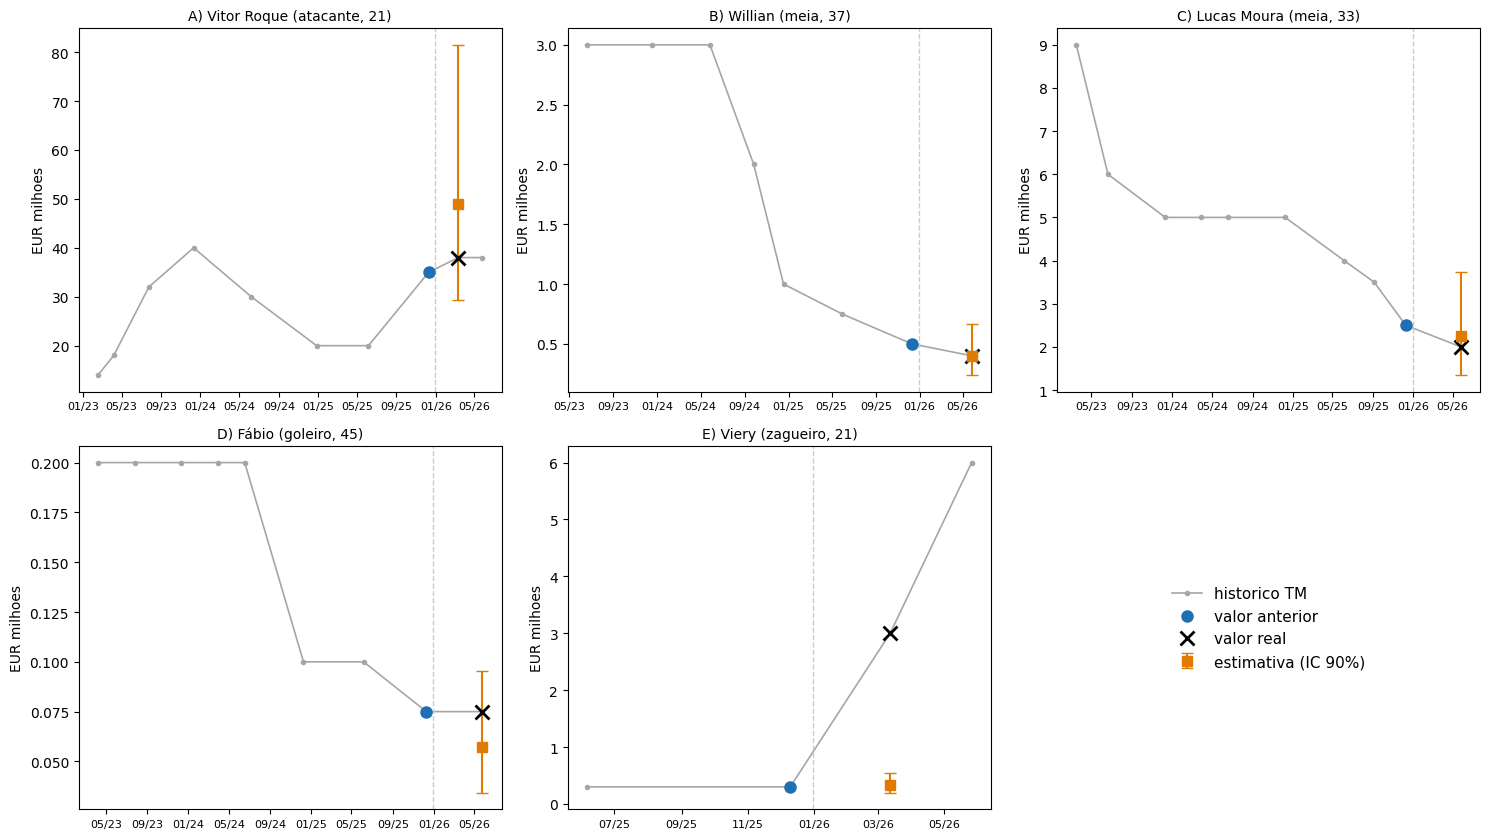

In [42]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

fig, axes = plt.subplots(2, 3, figsize=(15, 8.5))
for ax, (titulo, i) in zip(axes.ravel(), REGRAS.items()):
    r = casos.loc[i]
    h = val_c[(val_c["player_id"] == r["player_id"]) &
              (val_c["date"] >= r["d_ant"] - pd.DateOffset(years=3)) &
              (val_c["date"] <= r["data_alvo"] + pd.DateOffset(months=6))].sort_values("date")
    ax.plot(h["date"], h["market_value_in_eur"] / 1e6, "-o", color="0.65", ms=3, lw=1.2, label="historico TM")
    ax.axvline(pd.Timestamp(f"{int(r['temporada'])}-12-31"), color="0.8", ls="--", lw=1)
    ax.plot(r["d_ant"], r["v_ant"] / 1e6, "o", color="#1f6fb4", ms=8, label="valor anterior")
    ax.errorbar(r["data_alvo"], r["estimativa"] / 1e6,
                yerr=[[(r["estimativa"] - r["inf90"]) / 1e6], [(r["sup90"] - r["estimativa"]) / 1e6]],
                fmt="s", color="#e07b00", capsize=4, ms=7, label="estimativa (IC 90%)")
    ax.plot(r["data_alvo"], r["market_value_in_eur"] / 1e6, "x", color="black", ms=10, mew=2, label="valor real")
    ax.set_title(f"{titulo[:2]} {r['nome']} ({r['posicao']}, {r['idade_no_corte']:.0f})", fontsize=10)
    ax.set_ylabel("EUR milhoes"); ax.xaxis.set_major_formatter(mdates.DateFormatter("%m/%y"))
    ax.tick_params(axis="x", labelsize=8)
axes.ravel()[-1].axis("off")
h_, l_ = axes.ravel()[0].get_legend_handles_labels()
axes.ravel()[-1].legend(h_, l_, loc="center", fontsize=11, frameon=False)
plt.tight_layout(); plt.savefig(f"{CKPT}/casos_individuais.png", dpi=200, bbox_inches="tight"); plt.show()

### Exportacoes: estimativa x taxa paga

Quatro vendas BRA1 -> Europa da Secao 5, tambem por regra fixa: a de maior taxa, a mais proxima
da estimativa, a de maior premio e a de maior desconto. O modelo usado em cada venda e o da
temporada de referencia, treinado sem o jogador.

In [43]:
ap = aplicacao.copy()
ap["nome"] = ap["player_id"].map(nome_de).fillna(ap.get("player_name", ""))
REGRAS_EXP = {
    "Maior taxa paga":              ap["transfer_fee"].idxmax(),
    "Mais proxima da estimativa":   ap["premio_relativo"].abs().idxmin(),
    "Maior premio sobre estimativa": ap["premio_relativo"].idxmax(),
    "Maior desconto sobre estimativa": ap["premio_relativo"].idxmin(),
}
for titulo, i in REGRAS_EXP.items():
    r = ap.loc[i]
    print("=" * 80); print(titulo); print("-" * 80)
    print(f"{r['nome']} | {r.get('from_club_name','?')} -> {r.get('to_club_name','?')} "
          f"| {pd.to_datetime(r['transfer_date']):%d/%m/%Y} | temporada de referencia {int(r['temporada_ref'])}")
    print(f"  valor anterior ao corte    EUR {r['v_ant']:>12,.0f}")
    print(f"  variacao prevista          {np.expm1(r['delta_prev']):>+19.1%}")
    print(f"  estimativa do modelo       EUR {r['valor_estimado']:>12,.0f}")
    print(f"  valor TM na data da venda  EUR {r['market_value_in_eur']:>12,.0f}")
    print(f"  taxa paga                  EUR {r['transfer_fee']:>12,.0f}   "
          f"(premio sobre a estimativa {r['premio_relativo']:+.0%})\n")

Maior taxa paga
--------------------------------------------------------------------------------
Endrick | Palmeiras -> Real Madrid | 21/07/2024 | temporada de referencia 2023
  valor anterior ao corte    EUR   45,000,000
  variacao prevista                       +27.0%
  estimativa do modelo       EUR   57,142,923
  valor TM na data da venda  EUR   60,000,000
  taxa paga                  EUR   47,500,000   (premio sobre a estimativa -17%)

Mais proxima da estimativa
--------------------------------------------------------------------------------
Alysson | Grêmio -> Aston Villa | 01/01/2026 | temporada de referencia 2025
  valor anterior ao corte    EUR    8,000,000
  variacao prevista                       +26.4%
  estimativa do modelo       EUR   10,110,481
  valor TM na data da venda  EUR    8,000,000
  taxa paga                  EUR   10,000,000   (premio sobre a estimativa -1%)

Maior premio sobre estimativa
-------------------------------------------------------------------------

> **Como usar no artigo.** Um ou dois casos (por exemplo, A e C) bastam no texto, com a ficha
> resumida e o grafico; os demais podem ir para o apendice. Sempre informar a regra de selecao,
> para que o leitor saiba que o exemplo nao foi escolhido por ser favoravel. Casos individuais
> **ilustram** o funcionamento do modelo; a evidencia de desempenho continua sendo o painel de
> metricas da Secao 4B.

---
## Riscos residuais a monitorar

1. **Treino pequeno nas primeiras particoes.** Testar 2022 deixa so 2020-2021 para treinar,
   menos os jogadores repetidos. Confira o tamanho impresso na Secao 4.
2. **`preco` do Cartola.** Reflete popularidade alem de desempenho. Rode com e sem.
3. **2025 como ano mais recente.** Os alvos caem em 2026 e podem ter comportamento atipico.
4. **Pareamento em torno de 64%.** Os nao pareados podem nao ser aleatorios - compare a
   distribuicao de posicao e jogos entre pareados e nao pareados antes de escrever.
5. **Alvo e estimativa do Transfermarkt**, nao preco de transacao. A Secao 5 existe para
   confrontar isso, e a limitacao deve constar no texto.

## Entregaveis

Tabela de viabilidade, taxas de pareamento nas duas bases, auditoria temporal com zero
violacoes, tabela de cobertura, e Ridge contra media trivial.